<a href="https://colab.research.google.com/github/Abhinandcmtech/AM.SC.P2ARI25001_AbhinandA_AIResumeAnalyser/blob/main/BrainTumor_XAI_S3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
gpu_available = torch.cuda.is_available()
if gpu_available:
    device_name = torch.cuda.get_device_name(0)
    total_memory = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"GPU Available: {gpu_available}")
    print(f"Device Name  : {device_name}")
    print(f"VRAM         : {total_memory:.1f} GB")
else:
    print("No GPU detected in this runtime.")

# Brain Tumor Slice Classification with a Concept Bottleneck

**Author:** Abhinand A (AM.SC.P2ARI25001)  
**Advisor:** Prof. Dr. Divya Udayan J  

Research prototype, not a clinical diagnostic system.
Use the upload cell, numerical preflight, then Auditable Explainability. Do not use Run All.
Existing experiments are preserved; historical slice-level training is not evidence of new-patient performance.

**[Open all saved files in Drive](https://drive.google.com/drive/folders/1yPfSuYVSLd91M-5lJ_z8DNkOkqF_V4Y_)** | **[Saved notebook copy](https://drive.google.com/file/d/1w6LAuaZcKEue-hZD2rZuRKzIlVDfV7qe/view)**


Actual model and audit workflow


## Dataset Scope

The available BraTS2020 collection contains 17,116 MRI slices. The target is tumor presence within a slice; a tumor-negative slice does not establish a healthy patient. Patient-disjoint conclusions require documented volume-to-patient identity.


In [ ]:
import torch
print(f'PyTorch : {torch.__version__}')
print(f'GPU     : {torch.cuda.get_device_name(0)}')
print(f'VRAM    : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')

PyTorch : 2.11.0+cu128
GPU     : NVIDIA A100-SXM4-80GB
VRAM    : 85.1 GB


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
DATA_PATH = '/content/drive/MyDrive/BraTS2020/dataset/BraTS2020_training_data/content/data'

files = [f for f in os.listdir(DATA_PATH) if f.endswith('.h5')]
print(f'✅ {len(files):,} h5 files found')
print(f'   Sample: {sorted(files)[100]}')

Mounted at /content/drive
✅ 17,116 h5 files found
   Sample: volume_100_slice_5.h5


In [ ]:
print('Dependency checks run after the six source files are uploaded; core ML package versions are preserved.')


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 14.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
✅ Done


In [5]:
from google.colab import files
uploaded = files.upload()
print(f'✅ Uploaded: {list(uploaded.keys())}')

Saving module1_preprocessing.py to module1_preprocessing.py
Saving module2_model.py to module2_model.py
Saving module3_training.py to module3_training.py
Saving module4_explainability.py to module4_explainability.py
Saving test_reconstructed_modules.py to test_reconstructed_modules.py
Saving verify_checkpoint.py to verify_checkpoint.py
✅ Uploaded: ['module1_preprocessing.py', 'module2_model.py', 'module3_training.py', 'module4_explainability.py', 'test_reconstructed_modules.py', 'verify_checkpoint.py']


In [ ]:
from pathlib import Path
import hashlib, json, importlib.util, subprocess, sys

PREFLIGHT_RUN_DIR = Path('/content/drive/MyDrive/BraTS2020/ablation_study/stage2_seed42_2f00b2b02fd1')
preflight_config = json.loads((PREFLIGHT_RUN_DIR / 'config.json').read_text())
for preflight_name, preflight_hash in preflight_config['module_sha256'].items():
    preflight_path = Path('/content') / preflight_name
    if not preflight_path.is_file() or hashlib.sha256(preflight_path.read_bytes()).hexdigest() != preflight_hash:
        raise RuntimeError(f'Training source mismatch: {preflight_name}')
print('PASS: preprocessing and model sources exactly match the completed Stage 2 run.')
preflight_packages = {'captum': 'captum', 'shap': 'shap', 'lime': 'lime', 'skimage': 'scikit-image'}
preflight_missing = [package for module, package in preflight_packages.items() if importlib.util.find_spec(module) is None]
print('Missing explanation packages:', preflight_missing)
if preflight_missing:
    import importlib.metadata
    preflight_plan_path = Path('/content/xai_dependency_plan.json')
    preflight_plan = subprocess.run([sys.executable, '-m', 'pip', 'install', '--dry-run', '--report', str(preflight_plan_path), *preflight_missing], capture_output=True, text=True)
    if preflight_plan.returncode:
        raise RuntimeError(preflight_plan.stdout + preflight_plan.stderr)
    preflight_changes = json.loads(preflight_plan_path.read_text())['install']
    for preflight_package in preflight_changes:
        preflight_metadata = preflight_package['metadata']
        preflight_package_name = preflight_metadata['name'].lower().replace('_', '-')
        print('Dependency plan:', preflight_package_name, preflight_metadata['version'])
        if preflight_package_name in {'torch', 'torchvision', 'numpy'}:
            raise RuntimeError('Refusing to replace core training packages during explanation validation.')
    preflight_install = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *preflight_missing], capture_output=True, text=True)
    if preflight_install.returncode:
        raise RuntimeError(preflight_install.stdout + preflight_install.stderr)
    importlib.invalidate_caches()
import torch, unittest
preflight_threads = torch.get_num_threads()
try:
    torch.set_num_threads(2)
    preflight_suite = unittest.defaultTestLoader.loadTestsFromName('test_reconstructed_modules')
    preflight_result = unittest.TextTestRunner(verbosity=2).run(preflight_suite)
finally:
    torch.set_num_threads(preflight_threads)
if not preflight_result.wasSuccessful():
    raise RuntimeError('Numerical validation failed; do not generate explanation claims.')
XAI_PREFLIGHT_PASSED = True
print('LIVE_NUMERICAL_PREFLIGHT_PASSED', preflight_result.testsRun, 'tests;', len(preflight_result.skipped), 'skips')


✅ Config ready
   DATA_PATH  : /content/drive/MyDrive/BraTS2020/dataset/BraTS2020_training_data/content/data
   BATCH_SIZE : 32
   AMP        : True
   Epochs     : 30


Test Data Loading and Visualise

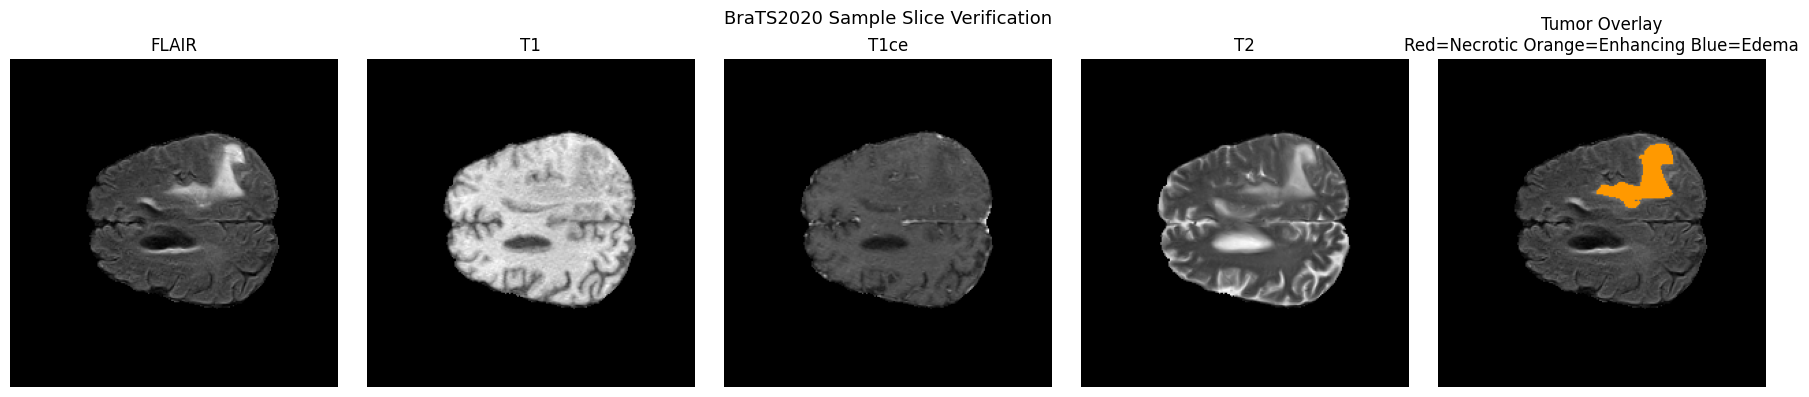

✅ Visualisation done


In [ ]:
print('Sample inspection is included in the audited explanation figures, with numerical coordinates and full-frame attribution.')


In [24]:
print('Legacy random-slice split retired: it can leak patients across train and test.')
print('Use the verified patient-group split in Stage 2 for new experiments.')


Legacy random-slice split retired: it can leak patients across train and test.
Use the verified patient-group split in Stage 2 for new experiments.


In [25]:
print('Legacy slice-split loaders retired. Stage 2 builds loaders from its saved patient manifest.')


Legacy slice-split loaders retired. Stage 2 builds loaders from its saved patient manifest.


In [26]:
print('The numerical preflight checks image shapes, native-resolution targets and model contracts.')


The numerical preflight checks image shapes, native-resolution targets and model contracts.


## Backbone Scope

The completed matched experiment uses ResNet50. Historical DenseNet and ResNeXt slice-split results are not unbiased new-patient comparisons. No plain-CNN baseline or multi-seed study has been completed here.


## Historical Training: Retired

The old random-slice training path is disabled. The corrected trainer is available in the uploaded module; new matched experiments require explicit provenance checks in Stage 2.


In [27]:
from module3_training import train_backbone
print('Corrected resumable trainer imported. No training starts automatically.')
print('Use the matched Stage 2 experiment below with verified patient provenance.')


Corrected resumable trainer imported. No training starts automatically.
Use the matched Stage 2 experiment below with verified patient provenance.


In [28]:
print('Legacy ResNet training disabled. Completed Stage 2 checkpoints remain unchanged.')


Legacy ResNet training disabled. Completed Stage 2 checkpoints remain unchanged.


In [29]:
print('Legacy DenseNet training disabled. No patient-disjoint DenseNet result is claimed.')


Legacy DenseNet training disabled. No patient-disjoint DenseNet result is claimed.


In [30]:
print('Legacy ResNeXt training disabled. No patient-disjoint ResNeXt result is claimed.')


Legacy ResNeXt training disabled. No patient-disjoint ResNeXt result is claimed.


In [31]:
print('Checkpoint copying retired. Historical checkpoint folders are never overwritten here.')


Checkpoint copying retired. Historical checkpoint folders are never overwritten here.


# Auditable Explainability

Run the numerical preflight in the Ablation Study section, then the preparation cell below.
The preparation scores the full saved test split before selecting seeded TP, TN, FP and FN examples.
Patient independence remains conditional on the saved volume-to-patient mapping; clinical coordinate meaning is not established.


## Prepare the Completed Stage 2 Model

Strict source and checkpoint checks precede explanation generation.
Training-only reference images are used for SHAP; original floating-point inputs are retained for LIME.
Reports go into a new timestamped folder without overwriting existing experiments.


In [14]:
from pathlib import Path
from module4_explainability import prepare_report, run_spatial_report, concept_interventions, write_rows
import pandas as pd
from unittest.mock import patch
from torch.utils.data import DataLoader

def xai_parallel_loader(*args, **kwargs):
    kwargs.update(num_workers=4, prefetch_factor=2)
    return DataLoader(*args, **kwargs)

XAI_RUN = True
XAI_RUN_DIR = Path('/content/drive/MyDrive/BraTS2020/ablation_study/stage2_seed42_2f00b2b02fd1')
XAI_DATA = Path('/content/drive/MyDrive/BraTS2020/dataset/BraTS2020_training_data/content/data')
XAI = None
if XAI_RUN:
    if not globals().get('XAI_PREFLIGHT_PASSED', False):
        raise RuntimeError('Run the numerical preflight cell in the Ablation Study section first.')
    with patch('torch.utils.data.DataLoader', xai_parallel_loader):
        XAI = prepare_report(
        XAI_DATA, XAI_RUN_DIR / 'audited_explanations',
        protocol='patient_disjoint', run_directory=XAI_RUN_DIR,
        variant='supervised_lambda1', seed=42, per_group=1, background_size=20,
        batch_size=8, concept_order_confirmed=False, trust_checkpoint=True)
    from module4_explainability import write_json
    write_json({'data_loader_workers': 4, 'prefetch_factor': 2, 'ordering': 'unchanged', 'serial_parallel_check': '8 samples exactly equal'}, XAI['directory'] / 'execution_settings.json')
    print('GROUPING LIMIT: saved volume-to-patient identity has not been independently verified.')
    print('SEMANTICS LIMIT: coordinates are not validated clinical concepts; inspect fidelity against constant baselines.')
    display(pd.read_csv(XAI['directory'] / 'concept_fidelity.csv'))
    print('XAI_PREPARATION_COMPLETE', XAI['directory'])
else:
    print('Explanation preparation is OFF.')


Scoring fixed test split: 8/2790
Scoring fixed test split: 208/2790
Scoring fixed test split: 408/2790
Scoring fixed test split: 608/2790
Scoring fixed test split: 808/2790
Scoring fixed test split: 1008/2790
Scoring fixed test split: 1208/2790
Scoring fixed test split: 1408/2790
Scoring fixed test split: 1608/2790
Scoring fixed test split: 1808/2790
Scoring fixed test split: 2008/2790
Scoring fixed test split: 2208/2790
Scoring fixed test split: 2408/2790
Scoring fixed test split: 2608/2790
Scoring fixed test split: 2790/2790
Selected groups: {'TP': {'available': 1020, 'selected': 1}, 'TN': {'available': 1535, 'selected': 1}, 'FP': {'available': 55, 'selected': 1}, 'FN': {'available': 180, 'selected': 1}}
Reports: /content/drive/MyDrive/BraTS2020/ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z
GROUPING LIMIT: saved volume-to-patient identity has not been independently verified.
SEMANTICS LIMIT: coordinates are not validated clinical concepts;

,coordinate,subset,mse,mae,zero_reference_mse,interpretation,training_mean_reference_mse
0,coordinate_0,all,0.092043,0.236268,0.000045,diagnostic_only,0.000038
1,coordinate_0,tumor_positive,0.014831,0.050252,0.000104,diagnostic_only,0.000078
2,coordinate_1,all,0.067206,0.157703,0.000150,diagnostic_only,0.000116
3,coordinate_1,tumor_positive,0.153214,0.356620,0.000349,diagnostic_only,0.000206
4,coordinate_2,all,0.117584,0.265583,0.000013,diagnostic_only,0.000012
5,coordinate_2,tumor_positive,0.019223,0.053503,0.000031,diagnostic_only,0.000023


XAI_PREPARATION_COMPLETE /content/drive/MyDrive/BraTS2020/ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z


## Coordinate Sensitivity

These interventions change internal model numbers, not tissue in a patient.
Coordinates are labelled numerically until target provenance and prediction fidelity are established.
A changed prediction demonstrates model sensitivity, not biological causation.


In [37]:
import numpy as np
import matplotlib.pyplot as plt
import module4_explainability as xai_reporting

def plot_audited_attribution(image, raw, brain, tumor, title, destination, signed=False):
    flair = image[0, 0].detach().cpu().numpy()
    maximum = float(np.abs(raw).max()) or 1.0
    lower = -maximum if signed else 0
    palette = 'RdBu_r' if signed else 'inferno'
    figure = plt.figure(figsize=(16, 4.5), layout='constrained')
    grid = figure.add_gridspec(1, 5, width_ratios=[1, 1, 1, 1, 0.045])
    axes = [figure.add_subplot(grid[0, column]) for column in range(4)]
    color_axis = figure.add_subplot(grid[0, 4])
    axes[0].imshow(flair, cmap='gray')
    if tumor.any() and not tumor.all():
        axes[0].contour(tumor, levels=[0.5], colors=['lime'], linewidths=0.8)
    axes[0].set_title('FLAIR + tumor outline', fontsize=11)
    rendered = axes[1].imshow(raw, cmap=palette, vmin=lower, vmax=maximum)
    axes[1].set_title('Unmasked attribution', fontsize=11)
    axes[2].imshow(raw * brain, cmap=palette, vmin=lower, vmax=maximum)
    axes[2].set_title('Nonzero-image proxy view', fontsize=11)
    axes[3].imshow(flair, cmap='gray')
    axes[3].imshow(raw, cmap=palette, vmin=lower, vmax=maximum, alpha=0.5)
    axes[3].set_title('Unmasked overlay', fontsize=11)
    for axis in axes:
        axis.axis('off')
    figure.colorbar(rendered, cax=color_axis)
    legend = 'Red=positive, blue=negative' if signed else 'Positive tumor-score evidence'
    figure.suptitle(title + '\n' + legend + '; per-example colour scale', fontsize=12)
    figure.savefig(destination, dpi=120)
    plt.close(figure)

xai_reporting.plot_attribution = plot_audited_attribution

from pathlib import Path
from IPython.display import Image, display
import pandas as pd

def run_audited_method(method):
    if globals().get('XAI') is None:
        raise RuntimeError('Complete the auditable explanation preparation cell first.')
    destination = XAI['directory'] / method
    rows = run_spatial_report(
        XAI['model'], XAI['selected'], XAI['background'], XAI['data_root'], destination,
        methods=(method,), seed=42, shap_samples=256, lime_samples=1000,
        concept_names=XAI['concept_names'])
    display(pd.DataFrame(rows))
    for record in XAI['selected']:
        display(Image(str(destination / (Path(record['filename']).stem + '_' + method + '.png'))))
    if method == 'gradcam':
        display(pd.read_csv(destination / 'concept_sensitivity.csv'))
    print('AUDITED_METHOD_COMPLETE', method, destination)
    return rows

print('Audited method runner ready. Each method preserves raw arrays, figures and numerical diagnostics.')


Audited method runner ready. Each method preserves raw arrays, figures and numerical diagnostics.


## Interpretation Limits

The saved supervised model has better ROC-AUC than the unsupervised bottleneck in this single-seed comparison.
Its coordinate errors are nevertheless worse than the training-mean baseline; clinically accurate concepts are not demonstrated.
Test-patient bootstrap intervals do not measure variation between training seeds.


## Spatial Explanations

Use the raw maps and numerical diagnostics together. Heatmaps alone do not establish clinical usefulness or causal validity.


## **Gradcam**

Explaining 1/4: volume_177_slice_35 | FP | P(tumor)=0.563
Explaining 2/4: volume_197_slice_55 | FN | P(tumor)=0.347
Explaining 3/4: volume_114_slice_62 | TP | P(tumor)=0.596
Explaining 4/4: volume_167_slice_7 | TN | P(tumor)=0.333


,filename,method,head_randomization_spearman,deletion_fraction,deletion_status,top_deleted_logit_drop,random_deleted_logit_drop_mean,top_deleted_probability_drop,random_deleted_probability_drop_mean,random_deleted_probability_drop_std,deletion_channels,abs_attribution_mass,brain_area_fraction,tumor_area_fraction,top_fraction,background_mass_fraction,tumor_mass_fraction,top_fraction_dice
0,volume_177_slice_35.h5,gradcam,-0.818499,0.1,zero_baseline_may_be_out_of_distribution,-0.018076,0.707180,-0.004441,0.174411,0.018331,all_four_modalities,240.727706,1.0,0.000000,0.1,0.0,NaN,NaN
1,volume_197_slice_55.h5,gradcam,-0.225421,0.1,zero_baseline_may_be_out_of_distribution,0.032919,-0.319910,0.007425,-0.075663,0.017384,all_four_modalities,0.176093,1.0,0.001096,0.1,0.0,0.0,0.0
2,volume_114_slice_62.h5,gradcam,-0.791548,0.1,zero_baseline_may_be_out_of_distribution,-0.000253,0.222641,-0.000061,0.054559,0.005005,all_four_modalities,2.432953,1.0,0.008769,0.1,0.0,0.0,0.0
3,volume_167_slice_7.h5,gradcam,NaN,0.1,undefined_zero_attribution,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,1.0,0.000000,0.1,NaN,NaN,NaN


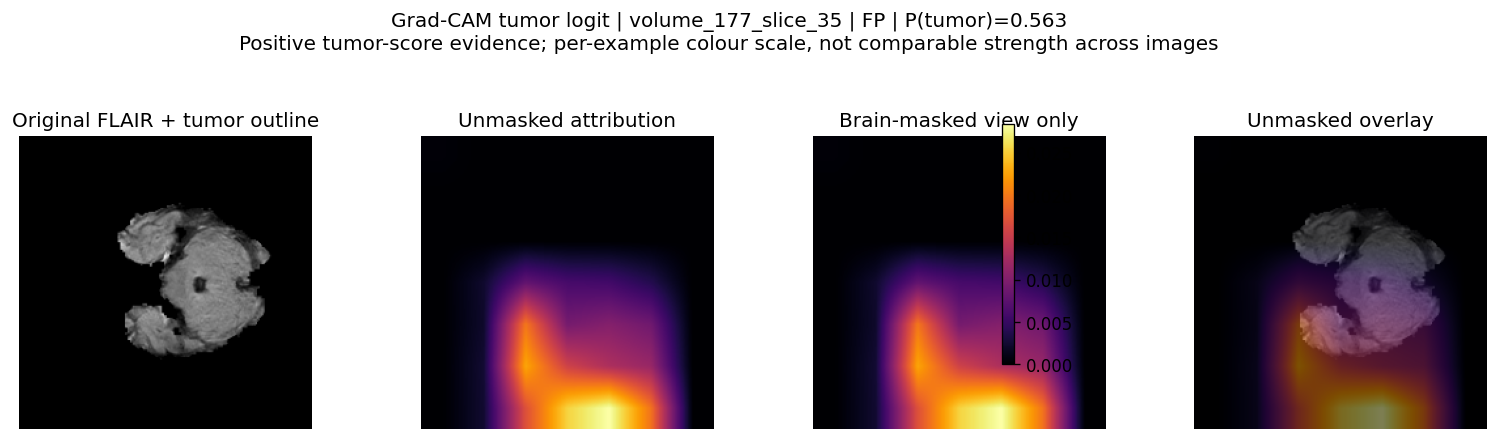

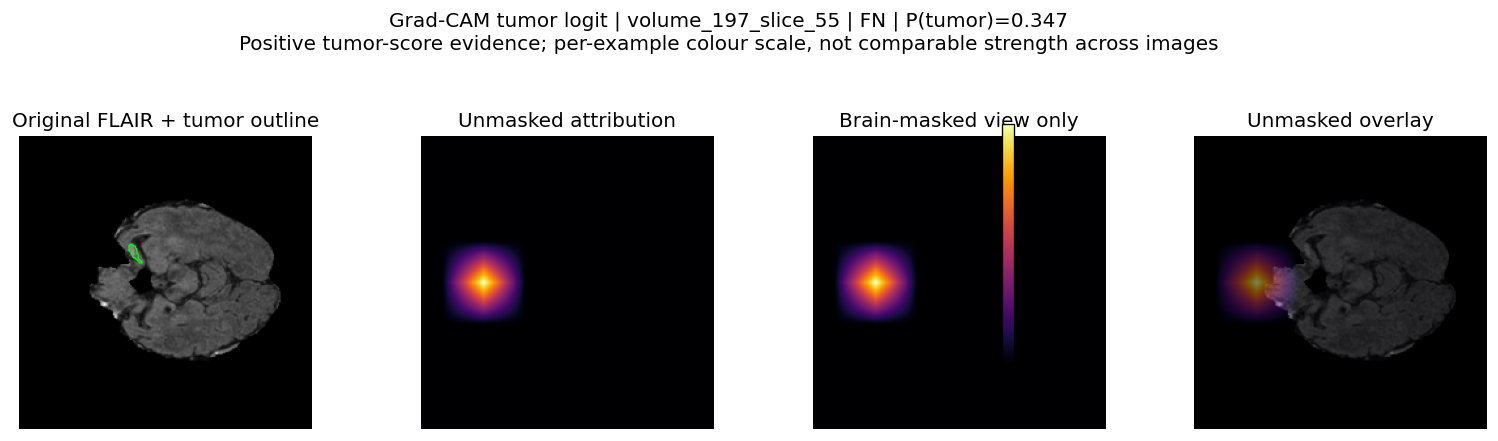

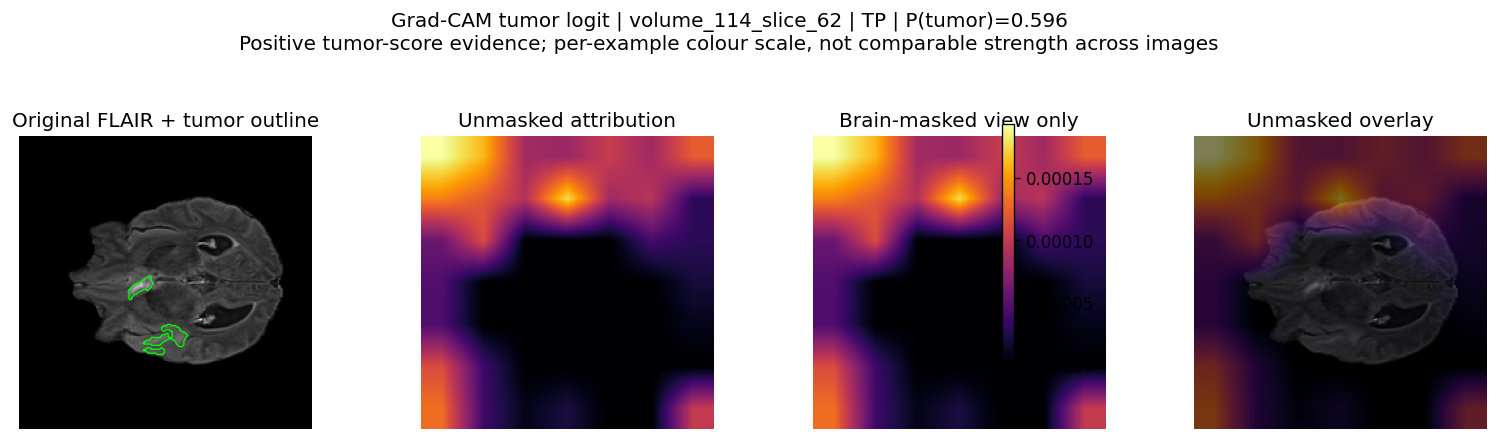

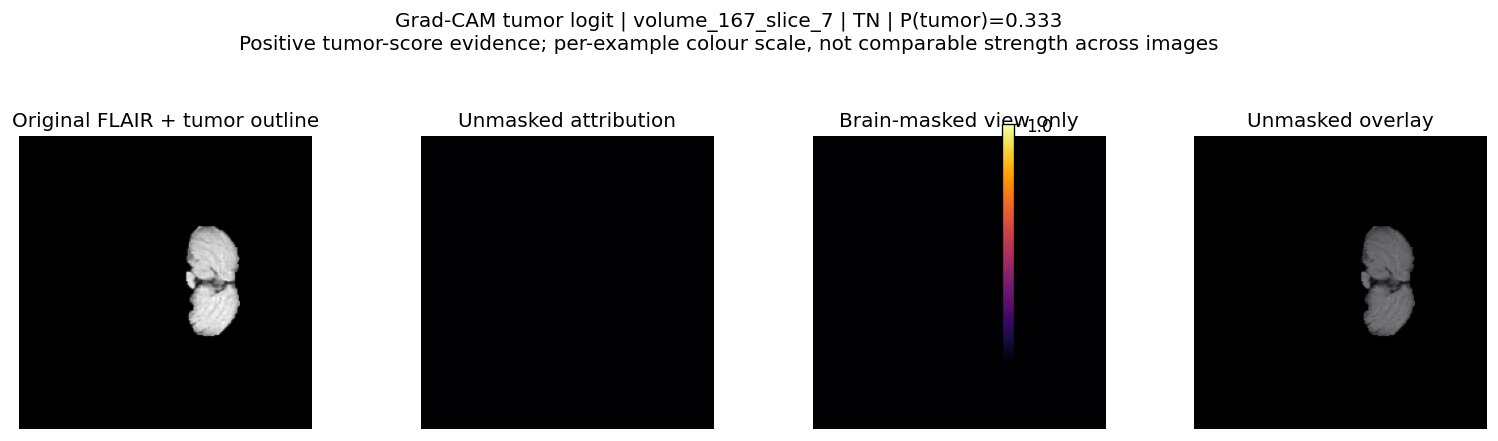

,filename,coordinate,original_value,baseline_probability,zeroed_probability,signed_change,absolute_change
0,volume_177_slice_35.h5,coordinate_0,1.043396e-03,0.563416,0.563624,0.000208,0.000208
1,volume_177_slice_35.h5,coordinate_1,2.699887e-01,0.563416,0.516740,-0.046676,0.046676
2,volume_177_slice_35.h5,coordinate_2,1.064785e-03,0.563416,0.563658,0.000242,0.000242
3,volume_197_slice_55.h5,coordinate_0,3.749819e-01,0.347342,0.419026,0.071684,0.071684
4,volume_197_slice_55.h5,coordinate_1,1.273575e-04,0.347342,0.347322,-0.000020,0.000020
5,volume_197_slice_55.h5,coordinate_2,4.287798e-01,0.347342,0.441502,0.094160,0.094160
6,volume_114_slice_62.h5,coordinate_0,5.515904e-12,0.595839,0.595839,0.000000,0.000000
7,volume_114_slice_62.h5,coordinate_1,4.584784e-01,0.595839,0.517197,-0.078642,0.078642
8,volume_114_slice_62.h5,coordinate_2,3.668831e-12,0.595839,0.595839,0.000000,0.000000
9,volume_167_slice_7.h5,coordinate_0,4.144578e-01,0.332679,0.410930,0.078251,0.078251


AUDITED_METHOD_COMPLETE gradcam /content/drive/MyDrive/BraTS2020/ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam


In [17]:
gradcam_results = run_audited_method('gradcam')


## Reading Grad-CAM

Inspect raw full-frame maps as well as explicitly labelled masked displays.
Background attribution, tumor overlap, deletion controls and randomized-head sensitivity are reported numerically.
Spatial overlap alone does not establish a faithful or clinically valid explanation.

**Observed audit:** the nonzero-image brain proxy covered the entire frame in all four cases, so zero measured background mass is not evidence that background cues were avoided. One tumor-negative Grad-CAM map was zero; its localization/deletion statistics are undefined.

### Saved GRADCAM Files

| File | Open |
|---|---|
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/concept_sensitivity.csv | [Open](https://drive.google.com/file/d/1EyefJf_f_yvnSMoK-HRfJXJx9dNh1r_Y/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/method_settings.json | [Open](https://drive.google.com/file/d/1T-cW5xPjLQTDl6nNu50azhkLYP9rRwJ0/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/spatial_metrics.csv | [Open](https://drive.google.com/file/d/19-3scrTnH_GZiAoukgYBGMN8BEKK4jxY/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/volume_114_slice_62_gradcam.npz | [Open](https://drive.google.com/file/d/1aJPKn4vnlV85H6DEbkPlmki4xVa54Wx_/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/volume_114_slice_62_gradcam.png | [Open](https://drive.google.com/file/d/1b7TPW2EDPz1j9T9EolXUJnAlinbCln_O/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/volume_167_slice_7_gradcam.npz | [Open](https://drive.google.com/file/d/1pRdDx-HSLoXq_Mz3QA7UkFzKlmoEDBbM/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/volume_167_slice_7_gradcam.png | [Open](https://drive.google.com/file/d/1deA1kAgpwgmZ4iRE0OABPxUR7VJxfToE/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/volume_177_slice_35_gradcam.npz | [Open](https://drive.google.com/file/d/1VEQhBa3dIqPlcAatH3eQrjYUKDJ7t8Za/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/volume_177_slice_35_gradcam.png | [Open](https://drive.google.com/file/d/1IvWap3fQjCxawS3ehI49A5uIGBj0GIAG/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/volume_197_slice_55_gradcam.npz | [Open](https://drive.google.com/file/d/1yidr_jS1tjptGzgvYHETT7Cy0XtJFty2/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/volume_197_slice_55_gradcam.png | [Open](https://drive.google.com/file/d/1x0AfbyAZQjWEL1rIBGOPd1Tv_NAoVwzr/view?usp=drivesdk) |


## **SHAP**

Explaining 1/4: volume_177_slice_35 | FP | P(tumor)=0.563
Explaining 2/4: volume_197_slice_55 | FN | P(tumor)=0.347
Explaining 3/4: volume_114_slice_62 | TP | P(tumor)=0.596
Explaining 4/4: volume_167_slice_7 | TN | P(tumor)=0.333


,filename,method,repeat_spearman,repeat_completeness_residual,modality_mean_absolute,deletion_fraction,deletion_status,top_deleted_logit_drop,random_deleted_logit_drop_mean,top_deleted_probability_drop,...,logit_difference_from_background,attribution_sum,completeness_residual,abs_attribution_mass,brain_area_fraction,tumor_area_fraction,top_fraction,background_mass_fraction,tumor_mass_fraction,top_fraction_dice
0,volume_177_slice_35.h5,shap,0.773556,-0.025695,"[0.0002534793902438614, 0.00022996810645273017...",0.1,zero_baseline_may_be_out_of_distribution,0.860373,0.707180,0.210292,...,0.656957,0.640480,0.016478,39.958082,1.0,0.000000,0.1,0.0,NaN,NaN
1,volume_197_slice_55.h5,shap,0.766977,-0.077299,"[8.397784504242692e-05, 0.00011837499821510209...",0.1,zero_baseline_may_be_out_of_distribution,-0.084832,-0.319910,-0.019471,...,-0.228826,-0.033251,-0.195574,18.478683,1.0,0.001096,0.1,0.0,0.002751,0.007096
2,volume_114_slice_62.h5,shap,0.760087,-0.025492,"[0.0001436677615945792, 0.00037354917000434316...",0.1,zero_baseline_may_be_out_of_distribution,0.389049,0.222641,0.096062,...,0.790074,0.777304,0.012770,38.437927,1.0,0.008769,0.1,0.0,0.111551,0.081348
3,volume_167_slice_7.h5,shap,0.673282,-0.067667,"[5.890908036576911e-05, 6.813177614994098e-05,...",0.1,zero_baseline_may_be_out_of_distribution,-0.022568,-0.016783,-0.005029,...,-0.294176,-0.249220,-0.044955,10.297357,1.0,0.000000,0.1,0.0,NaN,NaN


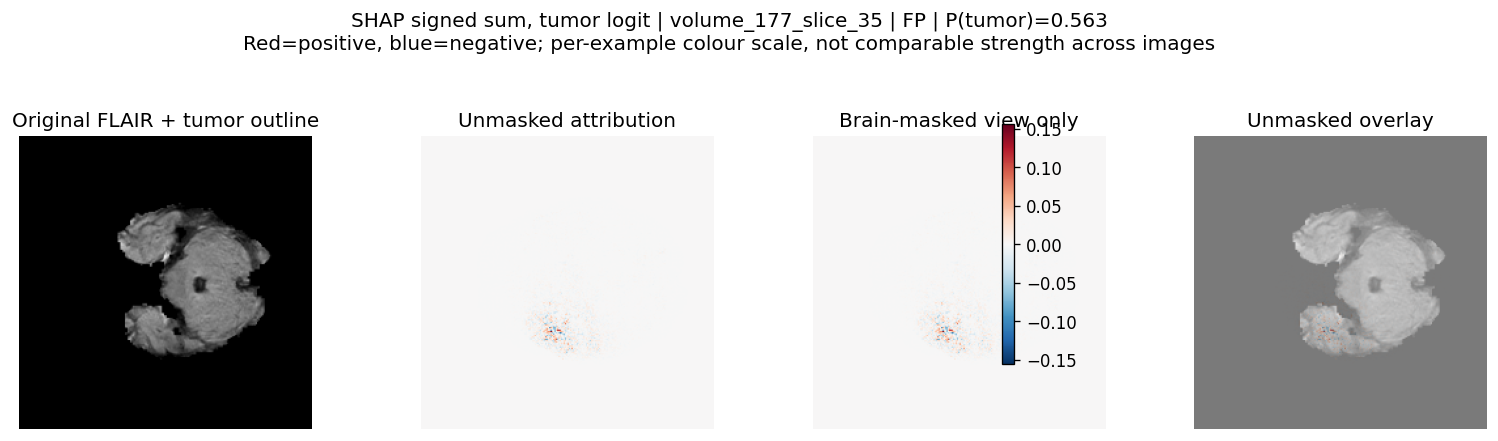

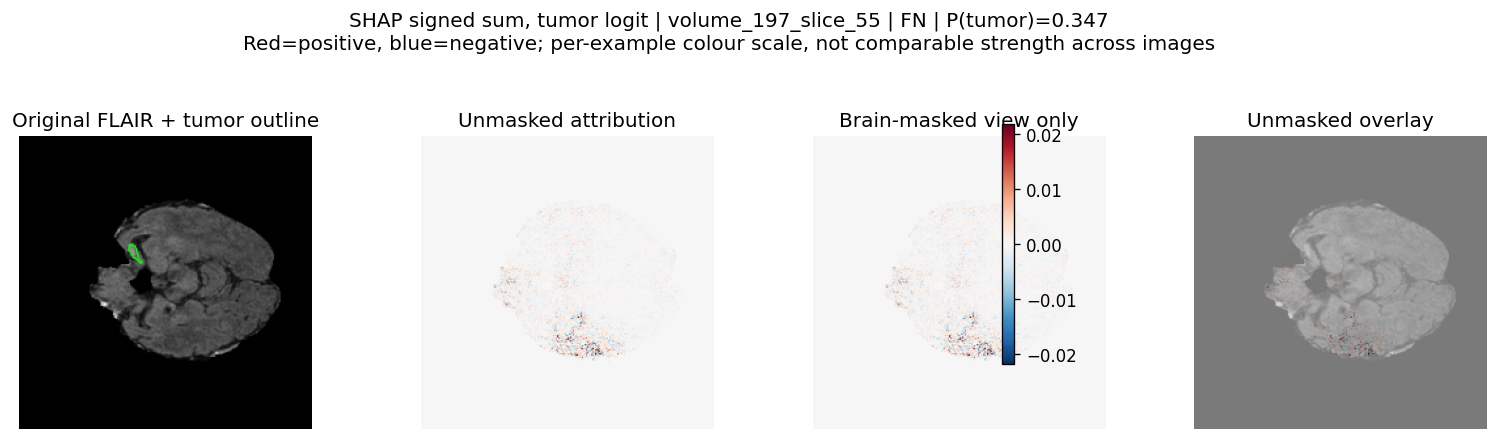

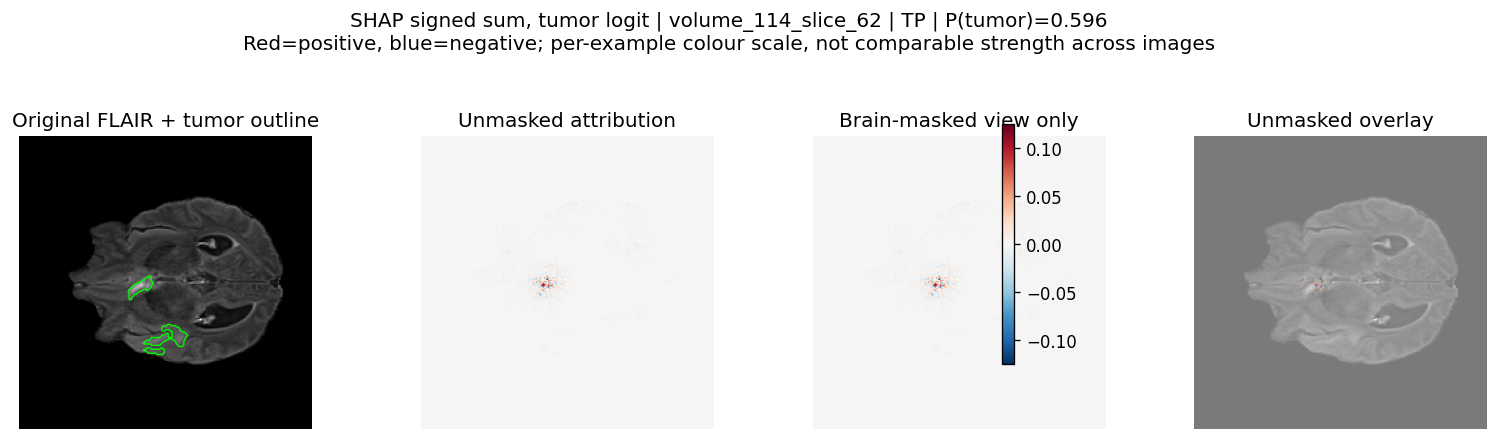

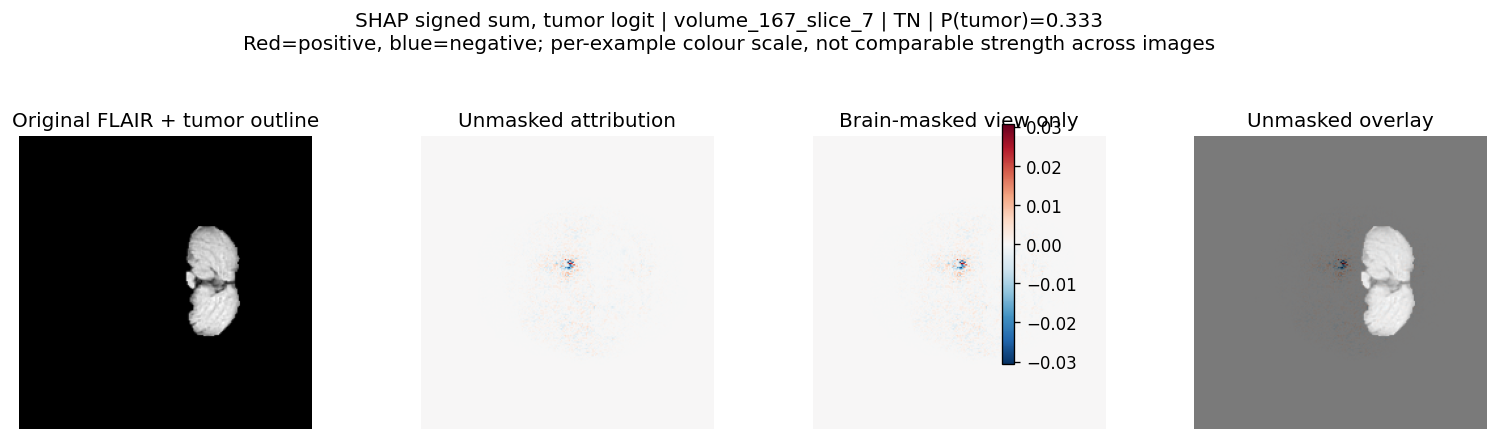

AUDITED_METHOD_COMPLETE shap /content/drive/MyDrive/BraTS2020/ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap


In [18]:
shap_results = run_audited_method('shap')


In [22]:
print('SHAP is computed once above; the report already includes a second-seed stability check.')


SHAP is computed once above; the report already includes a second-seed stability check.


## Reading SHAP

Expected-gradient estimates explain the tumor logit relative to selected training reference images.
Signed attributions, completeness residuals and repeatability are retained.
Modality contributions on selected cases are local diagnostics, not population-wide importance estimates.

**Observed audit:** seed-repeat Spearman correlations were about 0.67-0.77. One completeness residual was about -0.196 for a logit difference of -0.229, so that explanation has a substantial approximation error. These four selected cases do not estimate population-wide explanation quality.

### Saved SHAP Files

| File | Open |
|---|---|
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/concept_sensitivity.csv | [Open](https://drive.google.com/file/d/1B-At-GnH4JxTFgNUYHLj3vLxoOkvGNmu/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/method_settings.json | [Open](https://drive.google.com/file/d/1PHm13o_XRAREUK_VmgfnZratrFLu_lb0/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/spatial_metrics.csv | [Open](https://drive.google.com/file/d/1v8zxhz0e9oDu-Y4TRFVrUJZBRdYvdO_F/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/volume_114_slice_62_shap.npz | [Open](https://drive.google.com/file/d/1NEYmEUZrooKM5sWNXuE3cJzz9R_uNA6D/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/volume_114_slice_62_shap.png | [Open](https://drive.google.com/file/d/19YkeDIlNM2TGiJFrh2exHcdClSgN6wfd/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/volume_167_slice_7_shap.npz | [Open](https://drive.google.com/file/d/1w61gBQhcLINQ9fKX2cwOtEnUEGXjMyzV/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/volume_167_slice_7_shap.png | [Open](https://drive.google.com/file/d/1oLUxjgQDI9AZuWz35KvJOft1JEu6WKd6/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/volume_177_slice_35_shap.npz | [Open](https://drive.google.com/file/d/1ruqTu1qy7tWsvj8w2dQac2oUK1XGZdRC/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/volume_177_slice_35_shap.png | [Open](https://drive.google.com/file/d/1Ne6YnrH3wTZKSKoWX3U62JP7rV9n52YA/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/volume_197_slice_55_shap.npz | [Open](https://drive.google.com/file/d/1z_zc-i918h_c4RcQfCKcGL1eBy2DaD9u/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/volume_197_slice_55_shap.png | [Open](https://drive.google.com/file/d/1oMvCUJfDDpzIf6pWYGlW31bv3pAqd4X6/view?usp=drivesdk) |


## **LIME**

Explaining 1/4: volume_177_slice_35 | FP | P(tumor)=0.563


  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

Explaining 2/4: volume_197_slice_55 | FN | P(tumor)=0.347


  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

... (3 outputs left out)

Explaining 4/4: volume_167_slice_7 | TN | P(tumor)=0.333


  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

,filename,method,repeat_spearman,repeat_surrogate_r2,deletion_fraction,deletion_status,top_deleted_logit_drop,random_deleted_logit_drop_mean,top_deleted_probability_drop,random_deleted_probability_drop_mean,...,perturbations,superpixels,scope,abs_attribution_mass,brain_area_fraction,tumor_area_fraction,top_fraction,background_mass_fraction,tumor_mass_fraction,top_fraction_dice
0,volume_177_slice_35.h5,lime,0.683619,0.874643,0.1,zero_baseline_may_be_out_of_distribution,0.636953,0.611049,0.157751,0.150848,...,1000,39,FLAIR only; other modalities held fixed,612.126059,1.0,0.000000,0.1,0.0,NaN,NaN
1,volume_197_slice_55.h5,lime,0.674962,0.817883,0.1,zero_baseline_may_be_out_of_distribution,-0.249076,-0.047777,-0.058383,-0.010920,...,1000,37,FLAIR only; other modalities held fixed,206.711523,1.0,0.001096,0.1,0.0,0.007408,0.021683
2,volume_114_slice_62.h5,lime,0.639644,0.552204,0.1,zero_baseline_may_be_out_of_distribution,0.028652,0.005328,0.006918,0.001284,...,1000,40,FLAIR only; other modalities held fixed,200.998946,1.0,0.008769,0.1,0.0,0.032615,0.052400
3,volume_167_slice_7.h5,lime,0.287672,0.206340,0.1,zero_baseline_may_be_out_of_distribution,-0.034293,-0.004536,-0.007656,-0.001008,...,1000,46,FLAIR only; other modalities held fixed,25.250053,1.0,0.000000,0.1,0.0,NaN,NaN


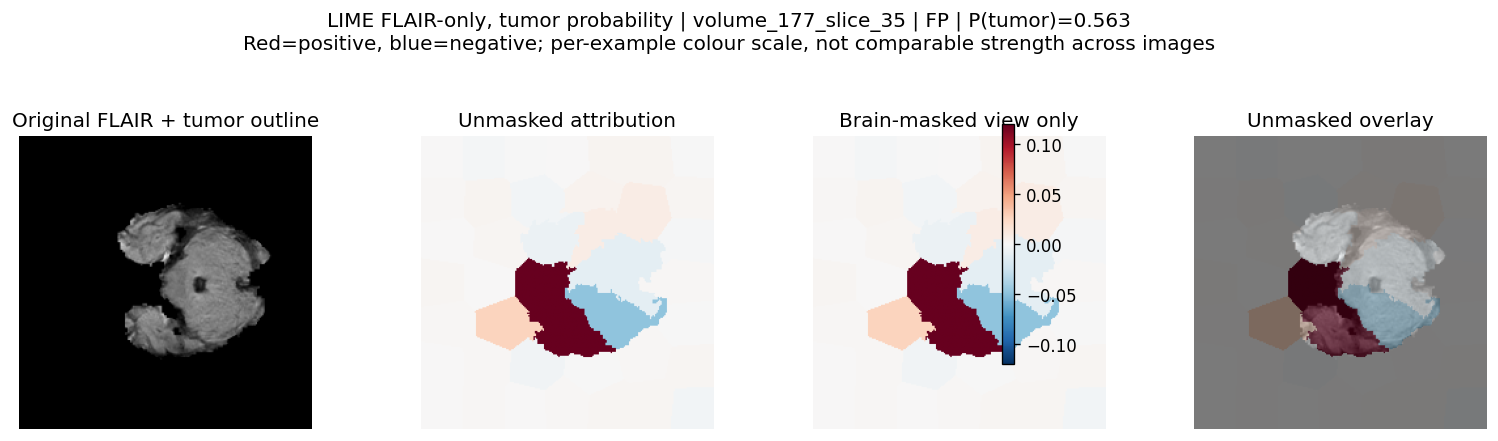

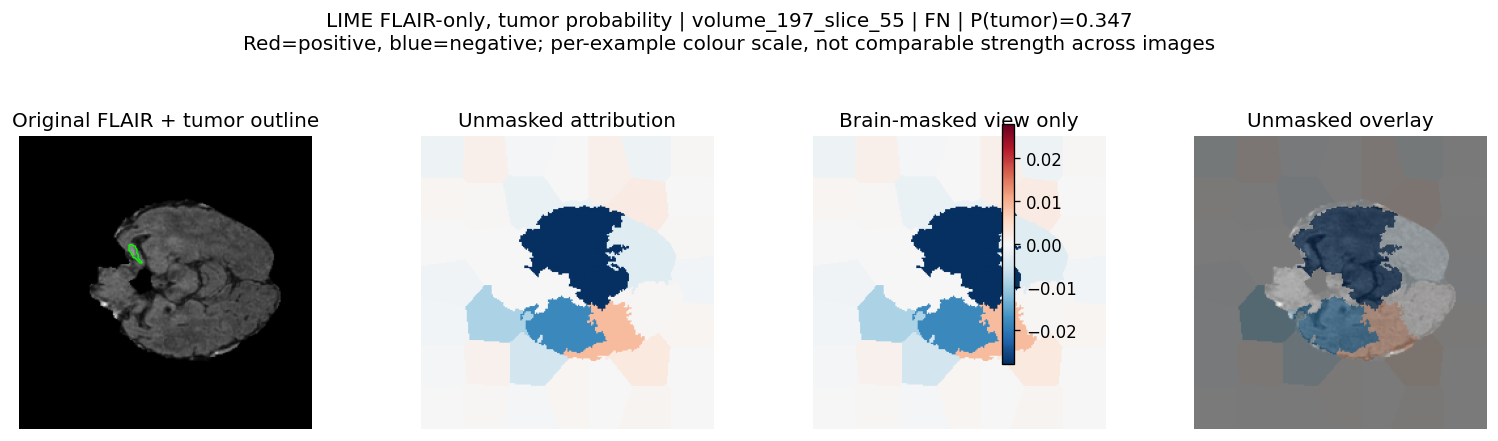

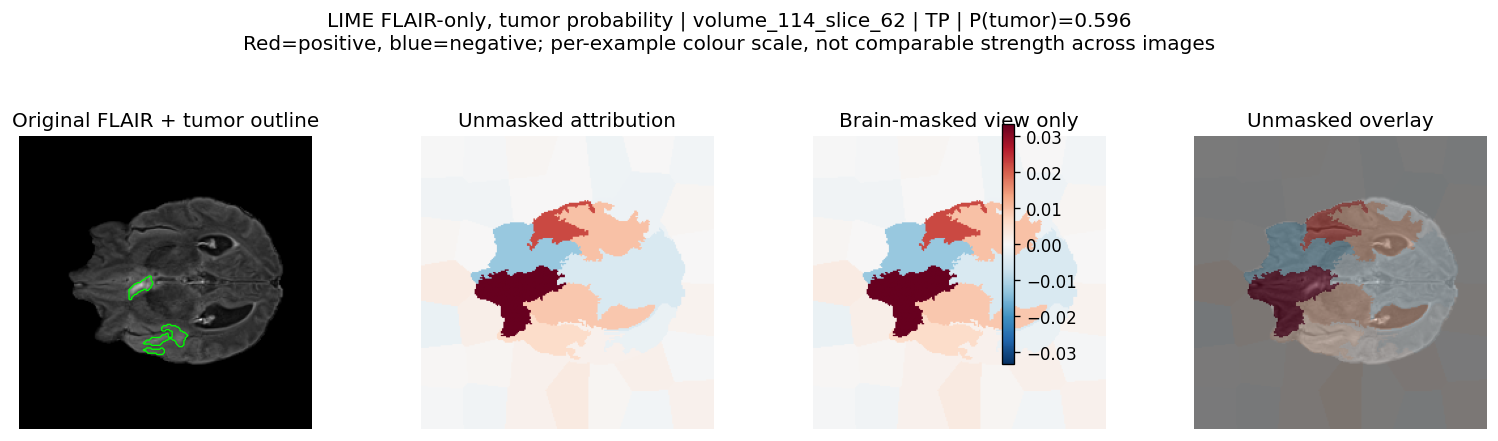

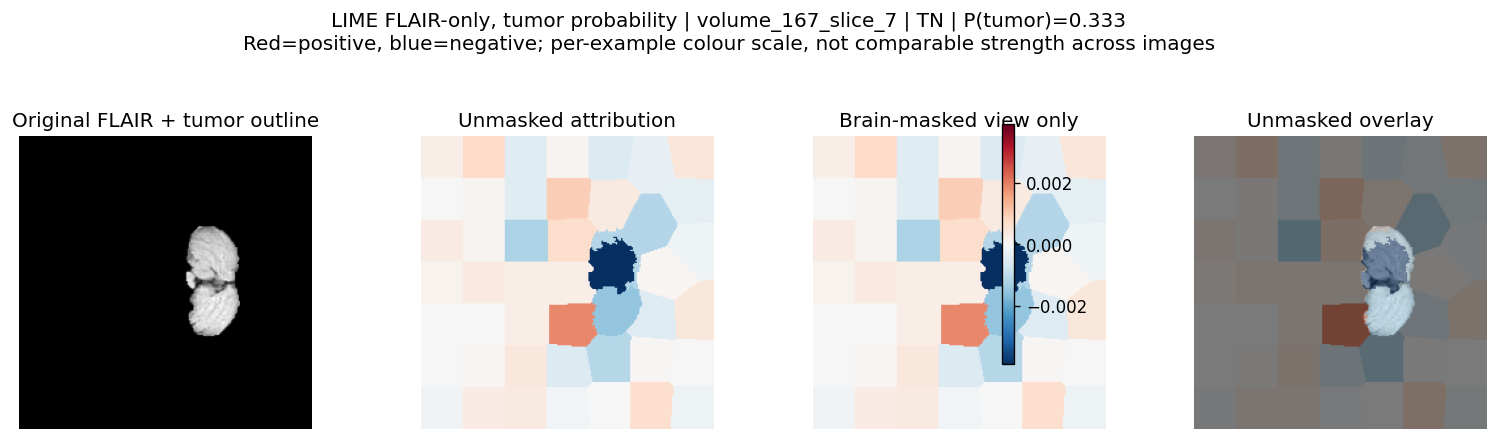

AUDITED_METHOD_COMPLETE lime /content/drive/MyDrive/BraTS2020/ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime


In [19]:
lime_results = run_audited_method('lime')


## Reading LIME

Only FLAIR patches are perturbed; T1, T1ce and T2 remain unchanged.
The unperturbed wrapper prediction must match the original model prediction; signed maps use their displayed colour bar.
Surrogate fit, prediction error and repeatability are diagnostics, not proof of tumor localization.

**Observed audit:** seed-repeat correlations ranged about 0.29-0.68; the repeated tumor-negative surrogate had R-squared about 0.21. Treat that explanation as weak and unstable, not clinically trustworthy.

### Saved LIME Files

| File | Open |
|---|---|
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/concept_sensitivity.csv | [Open](https://drive.google.com/file/d/1oO2rWuui_276kxPNa67AF9gnd7YhXUJu/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/method_settings.json | [Open](https://drive.google.com/file/d/1aB88dPqCShQXPoYywat3jzmvKXfhT3jp/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/spatial_metrics.csv | [Open](https://drive.google.com/file/d/1zn6j2jfjTjoKmjVdAYd5ZzOF4dlNNO3B/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/volume_114_slice_62_lime.npz | [Open](https://drive.google.com/file/d/1u9nj8_9a0w8C3BhTPSUDclCdDi7IKpMp/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/volume_114_slice_62_lime.png | [Open](https://drive.google.com/file/d/1eDNLUoUlteJPpltq-DvArNf8gs-4DfvA/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/volume_167_slice_7_lime.npz | [Open](https://drive.google.com/file/d/1KyWBRK_vE_n7Pe031vQYkyRCY0eg81jS/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/volume_167_slice_7_lime.png | [Open](https://drive.google.com/file/d/1XhFasXUSd2HIisFiyBGntP_4vibzoaBt/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/volume_177_slice_35_lime.npz | [Open](https://drive.google.com/file/d/1AkqzJApUirlYdXGDjWkB0hdG4_aznxJg/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/volume_177_slice_35_lime.png | [Open](https://drive.google.com/file/d/1mdvY6VanjJvUQ0zJ03mtFSmPkI2ts3kk/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/volume_197_slice_55_lime.npz | [Open](https://drive.google.com/file/d/1loWDVzvo3Gmb_Ps0VizBcsSc8rV6jQ4R/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/volume_197_slice_55_lime.png | [Open](https://drive.google.com/file/d/16CF1NnOuirdJCS3HnvgaRDg8RYP4r4iz/view?usp=drivesdk) |


## **Final Evaluation Dashboard**

In [20]:
from pathlib import Path
import pandas as pd
from IPython.display import display

review_run = Path('/content/drive/MyDrive/BraTS2020/ablation_study/stage2_seed42_2f00b2b02fd1')
review_metrics = pd.read_csv(review_run / 'test_comparison.csv')
review_concepts = pd.read_csv(review_run / 'concept_comparison.csv')
review_intervals = pd.read_csv(review_run / 'patient_bootstrap_ci.csv')
print('Saved completed-run results, one training seed; patient identity is conditional on the original mapping assertion.')
display(review_metrics)
display(review_concepts)
display(review_intervals.loc[review_intervals.comparison == 'unsupervised_minus_supervised'])
print('AP NOTE: the stored pr_auc column is average precision, not trapezoidal PR area.')
print('CONCEPT LIMIT: compare each MSE with constant_reference_mse before interpreting coordinate names clinically.')
if globals().get('XAI') is not None:
    from sklearn.metrics import roc_auc_score, accuracy_score
    current_predictions = pd.read_csv(XAI['directory'] / 'test_predictions.csv')
    print('Fresh supervised full-test ROC-AUC:', roc_auc_score(current_predictions.label, current_predictions.probability))
    print('Fresh supervised full-test accuracy:', accuracy_score(current_predictions.label, current_predictions.probability >= 0.5))


Saved completed-run results, one training seed; patient identity is conditional on the original mapping assertion.


,variant,best_epoch,accuracy,roc_auc,pr_auc,f1,sensitivity,specificity,tn,fp,fn,tp
0,supervised_lambda1,13,0.915771,0.969961,0.970037,0.896703,0.8500,0.965409,1535,55,180,1020
1,unsupervised_lambda0,10,0.922222,0.949443,0.947903,0.904110,0.8525,0.974843,1550,40,177,1023


,variant,concept_coordinate,subset,mse,mae,constant_reference_mse,constant_reference_mae
0,supervised_lambda1,edema,all,0.092044,0.236267,0.000038,0.004043
1,supervised_lambda1,edema,tumor_positive,0.014830,0.050252,0.000078,0.005869
2,supervised_lambda1,enhancing,all,0.067202,0.157696,0.000116,0.008190
3,supervised_lambda1,enhancing,tumor_positive,0.153202,0.356594,0.000206,0.009864
4,supervised_lambda1,necrotic,all,0.117569,0.265565,0.000012,0.002348
5,supervised_lambda1,necrotic,tumor_positive,0.019220,0.053500,0.000023,0.003204
6,unsupervised_lambda0,edema,all,0.615549,0.622799,0.000038,0.004043
7,unsupervised_lambda0,edema,tumor_positive,0.145224,0.156549,0.000078,0.005869
8,unsupervised_lambda0,enhancing,all,0.361047,0.370875,0.000116,0.008190
9,unsupervised_lambda0,enhancing,tumor_positive,0.814742,0.832752,0.000206,0.009864


,comparison,metric,point,ci95_low,ci95_high,valid_resamples,requested_resamples,test_patients
12,unsupervised_minus_supervised,roc_auc,-0.020518,-0.033275,-0.008345,500,500,18
13,unsupervised_minus_supervised,pr_auc,-0.022134,-0.032626,-0.012093,500,500,18
14,unsupervised_minus_supervised,accuracy,0.006452,-0.008432,0.023315,500,500,18
15,unsupervised_minus_supervised,f1,0.007406,-0.011579,0.030806,500,500,18
16,unsupervised_minus_supervised,sensitivity,0.002500,-0.034270,0.049366,500,500,18
17,unsupervised_minus_supervised,specificity,0.009434,-0.003839,0.021972,500,500,18


AP NOTE: the stored pr_auc column is average precision, not trapezoidal PR area.
CONCEPT LIMIT: compare each MSE with constant_reference_mse before interpreting coordinate names clinically.
Fresh supervised full-test ROC-AUC: 0.9700518867924528
Fresh supervised full-test accuracy: 0.9157706093189965


## **Plot Dashboard**

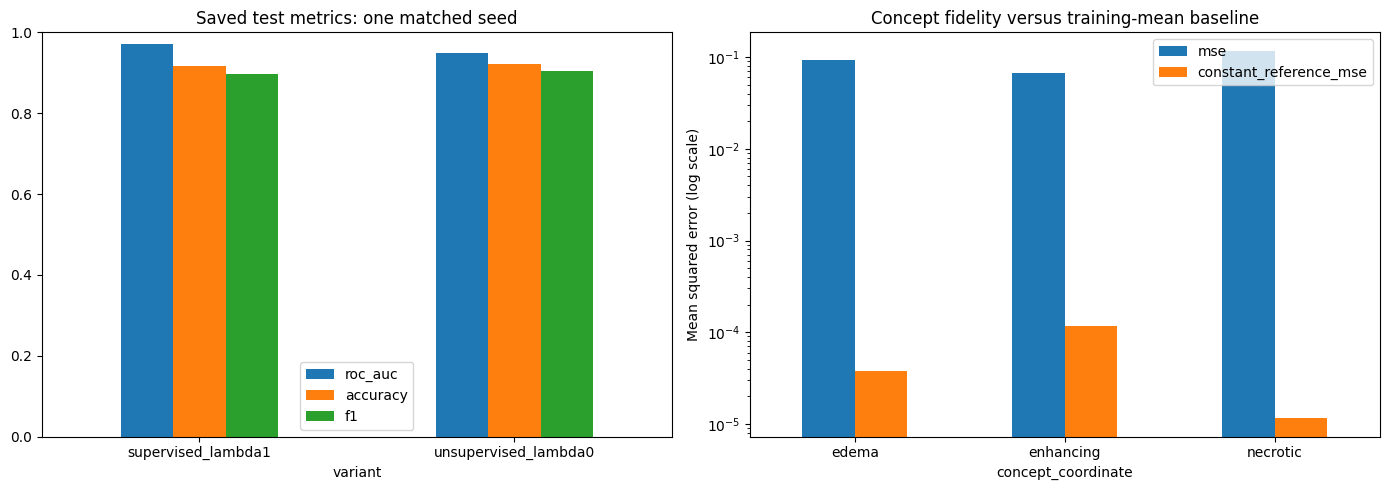

In [21]:
import matplotlib.pyplot as plt

if 'review_metrics' not in globals():
    raise RuntimeError('Read the completed-run result tables in the preceding cell first.')
figure, axes = plt.subplots(1, 2, figsize=(14, 5))
review_metrics.set_index('variant')[['roc_auc', 'accuracy', 'f1']].plot.bar(ax=axes[0], ylim=(0, 1), rot=0)
axes[0].set_title('Saved test metrics: one matched seed')
concept_view = review_concepts.loc[(review_concepts.variant == 'supervised_lambda1') & (review_concepts.subset == 'all')]
concept_view.set_index('concept_coordinate')[['mse', 'constant_reference_mse']].plot.bar(ax=axes[1], logy=True, rot=0)
axes[1].set_title('Concept fidelity versus training-mean baseline')
axes[1].set_ylabel('Mean squared error (log scale)')
figure.tight_layout()
if globals().get('XAI') is not None:
    figure.savefig(XAI['directory'] / 'reviewed_study_dashboard.png', dpi=150)
plt.show()


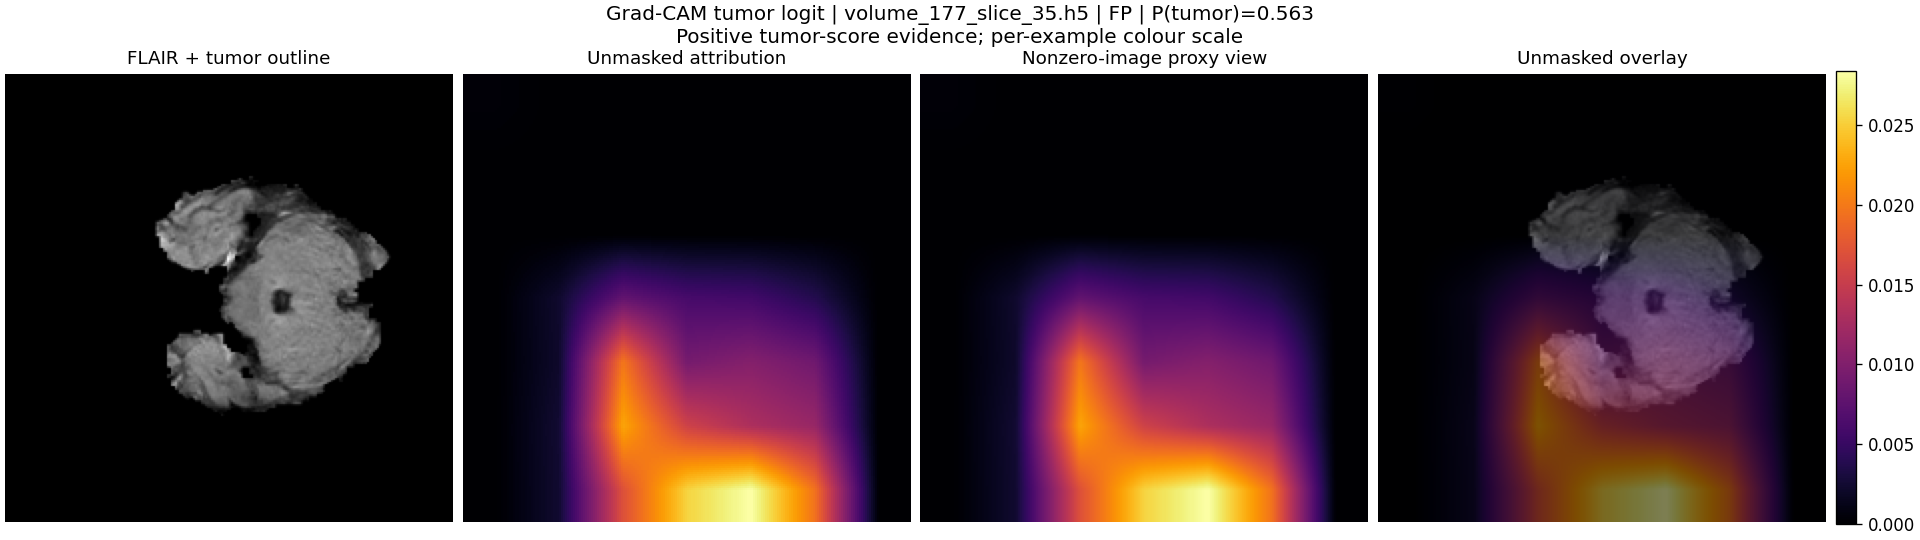

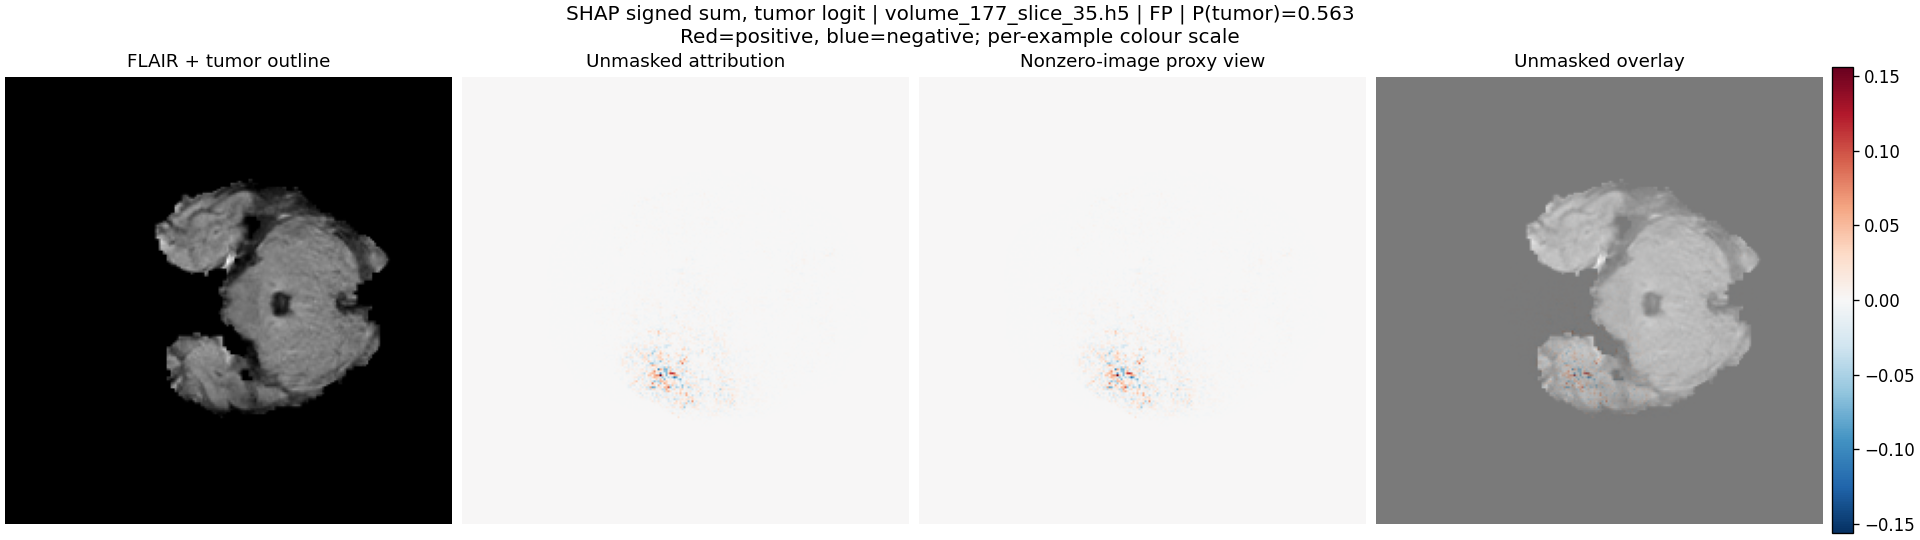

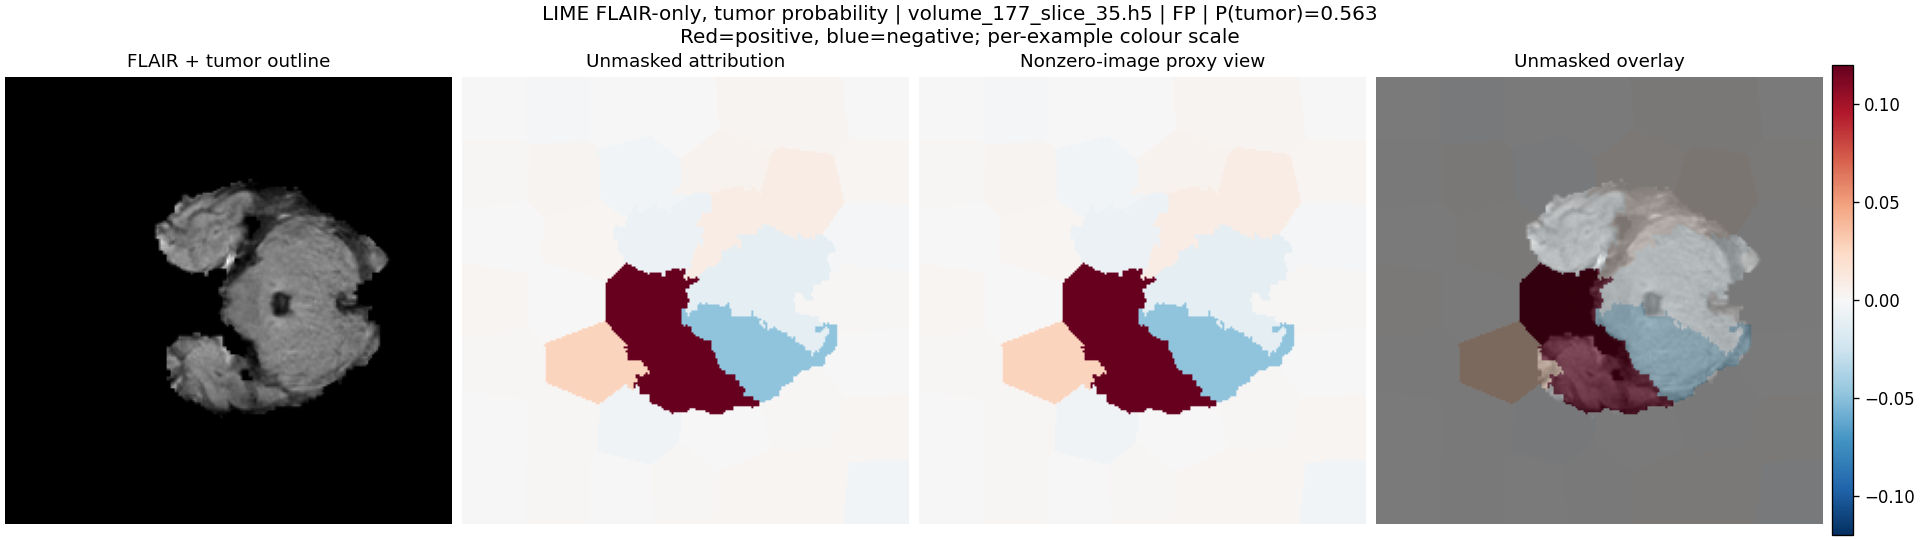

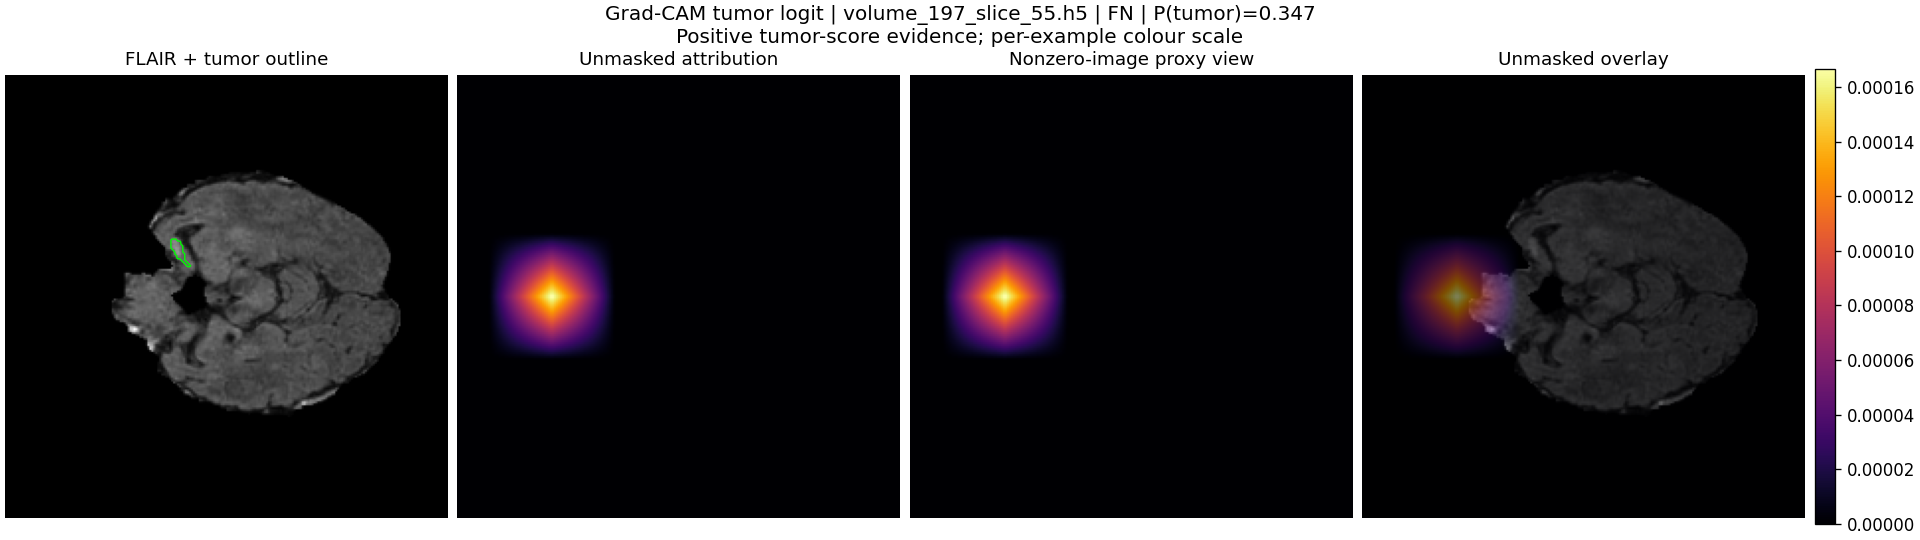

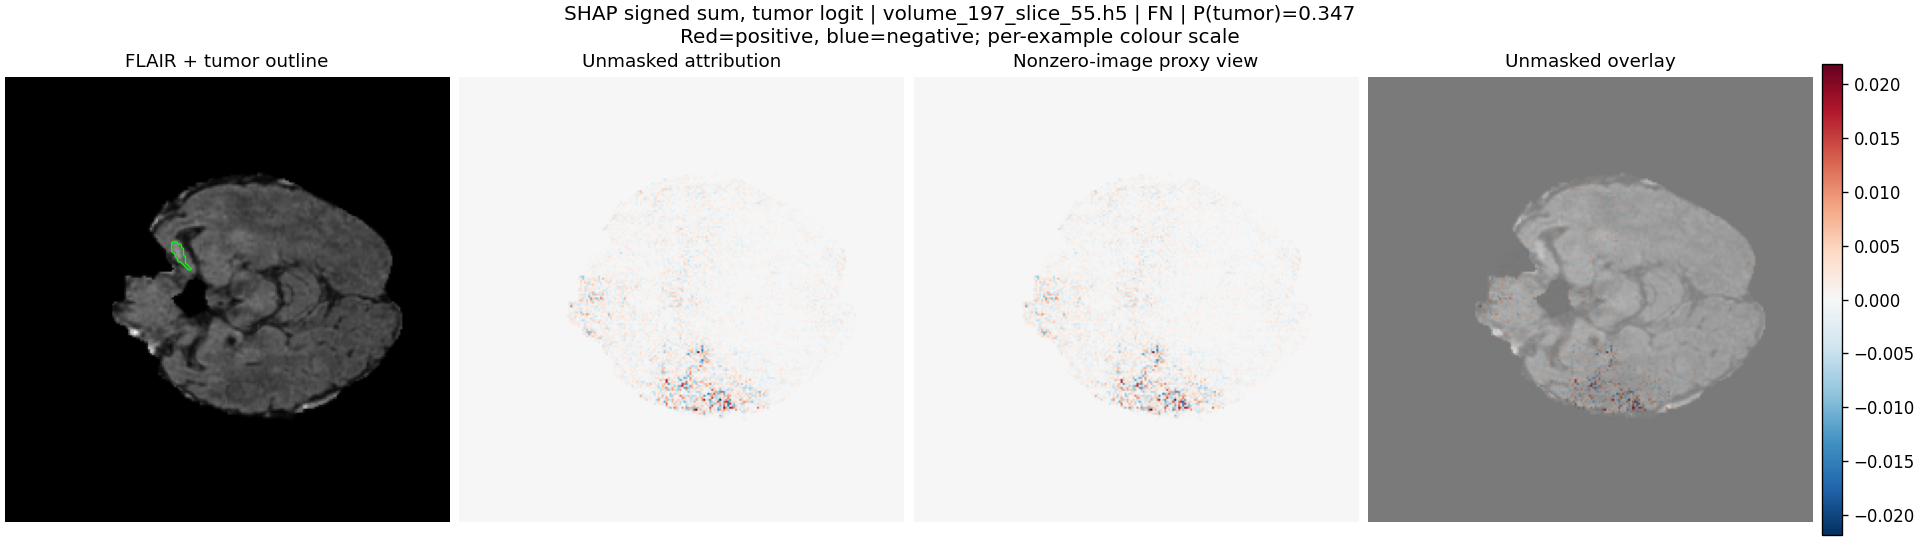

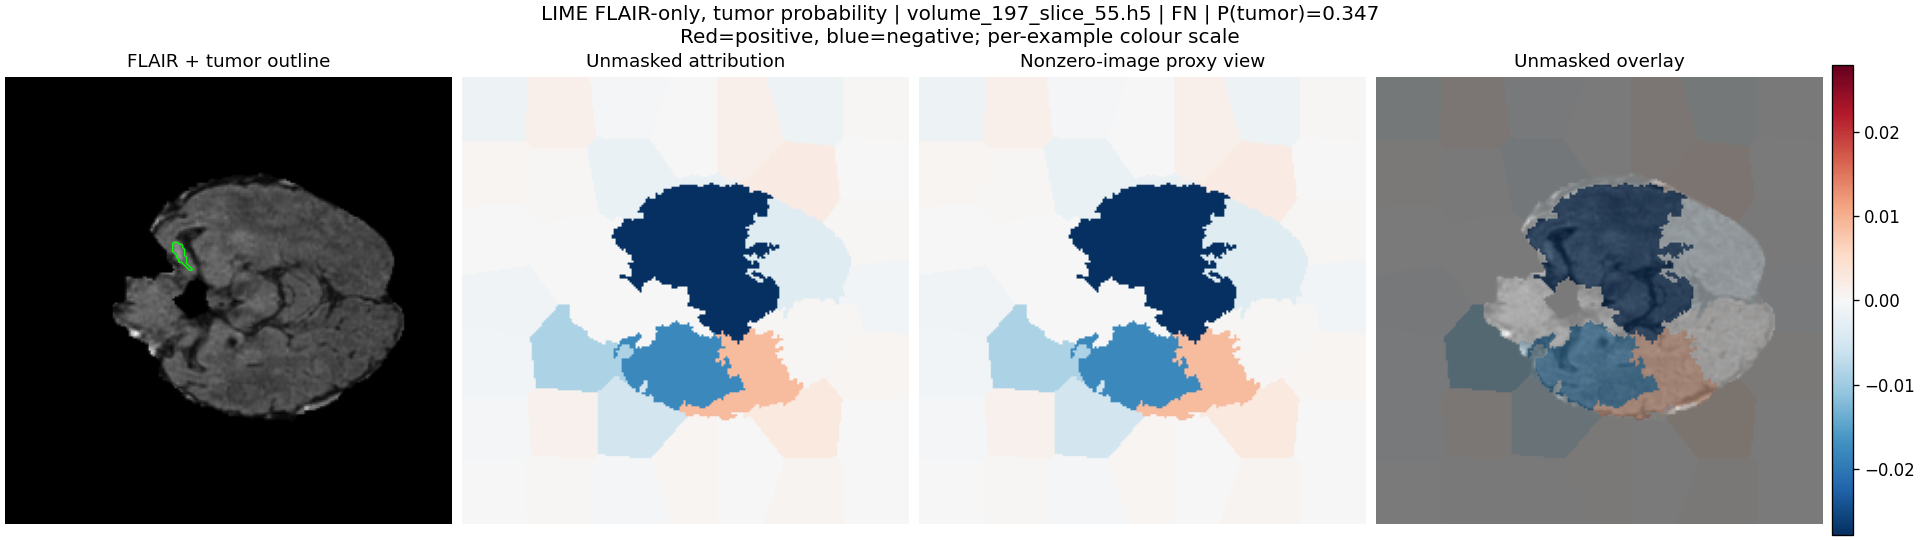

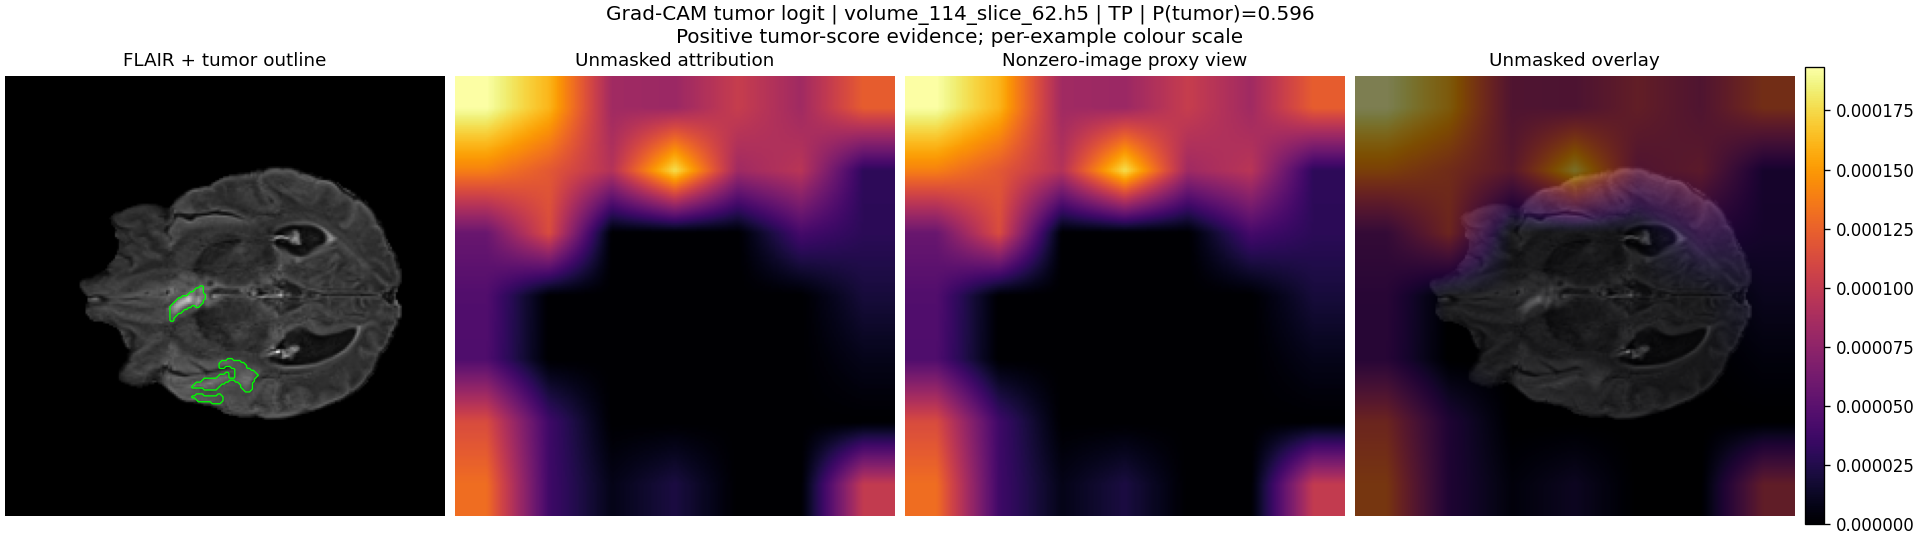

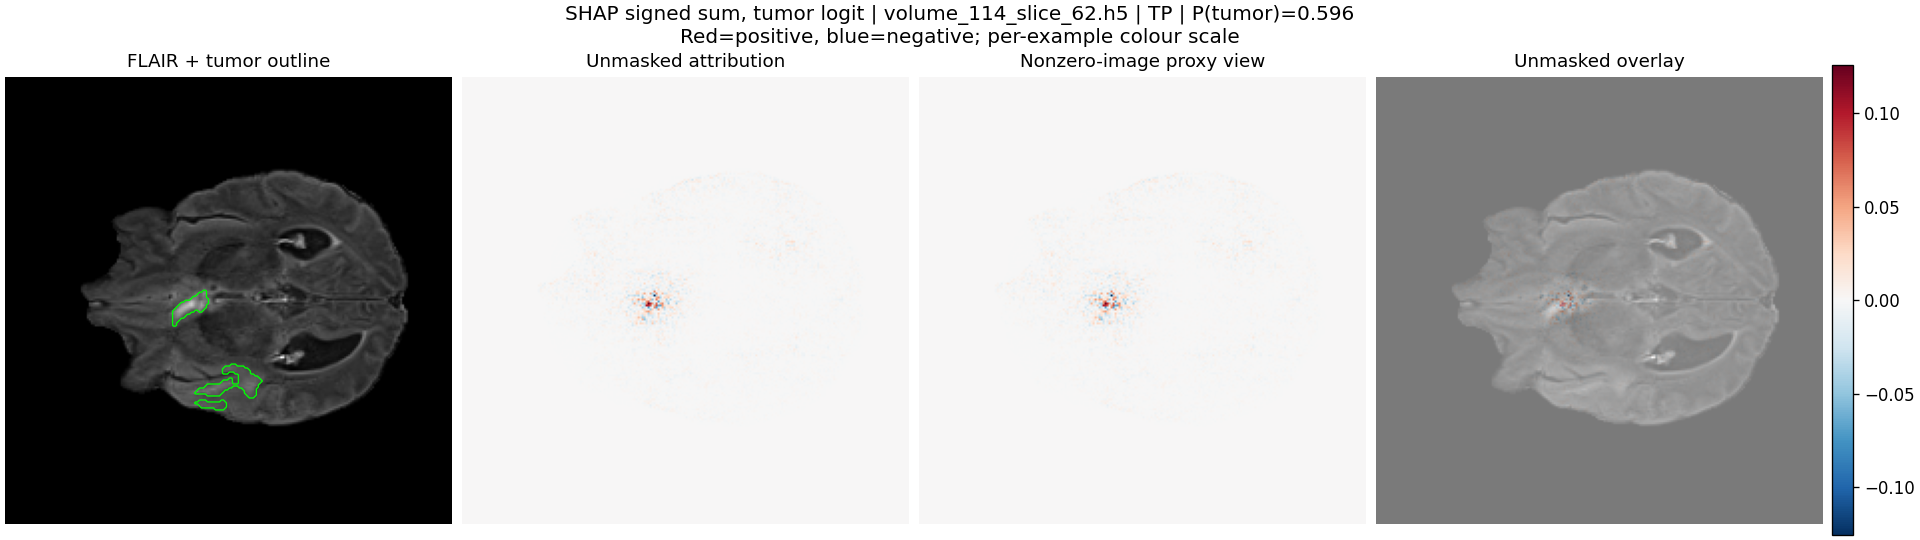

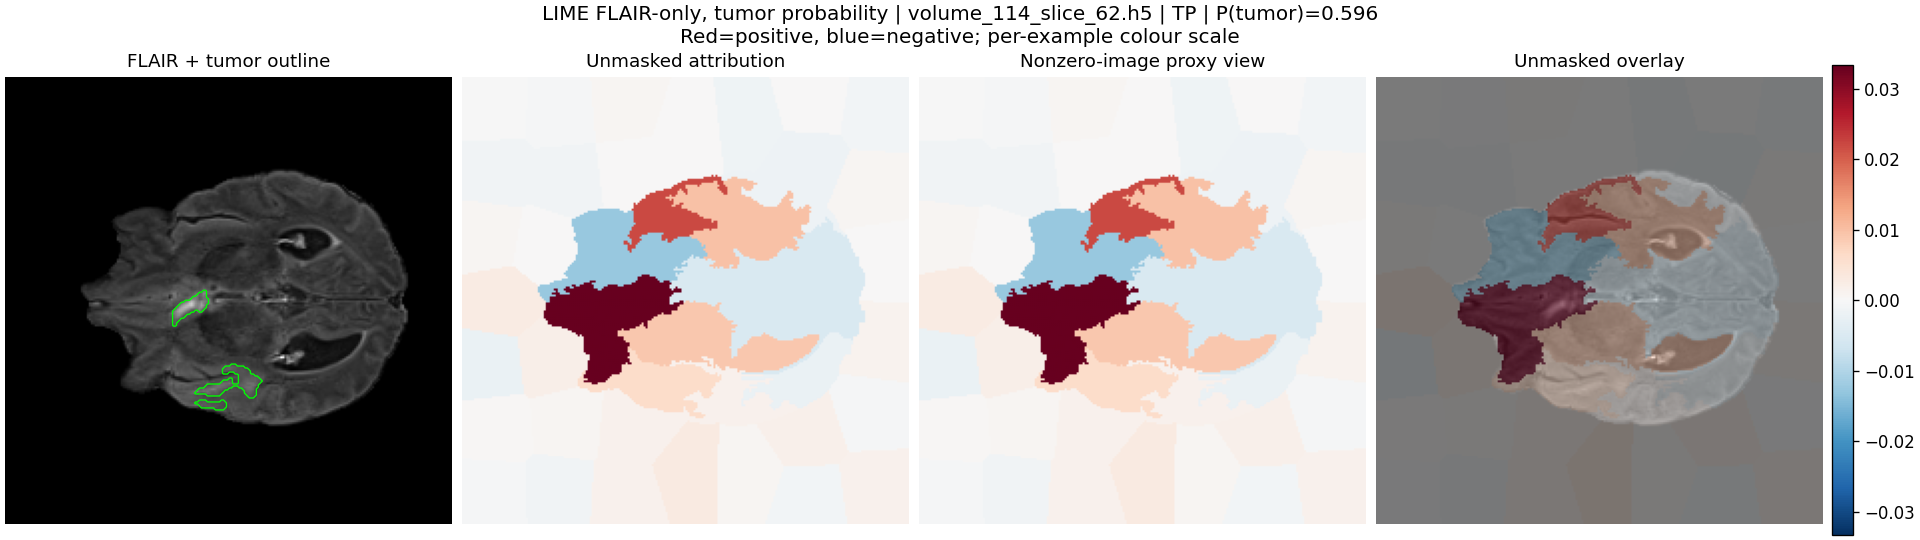

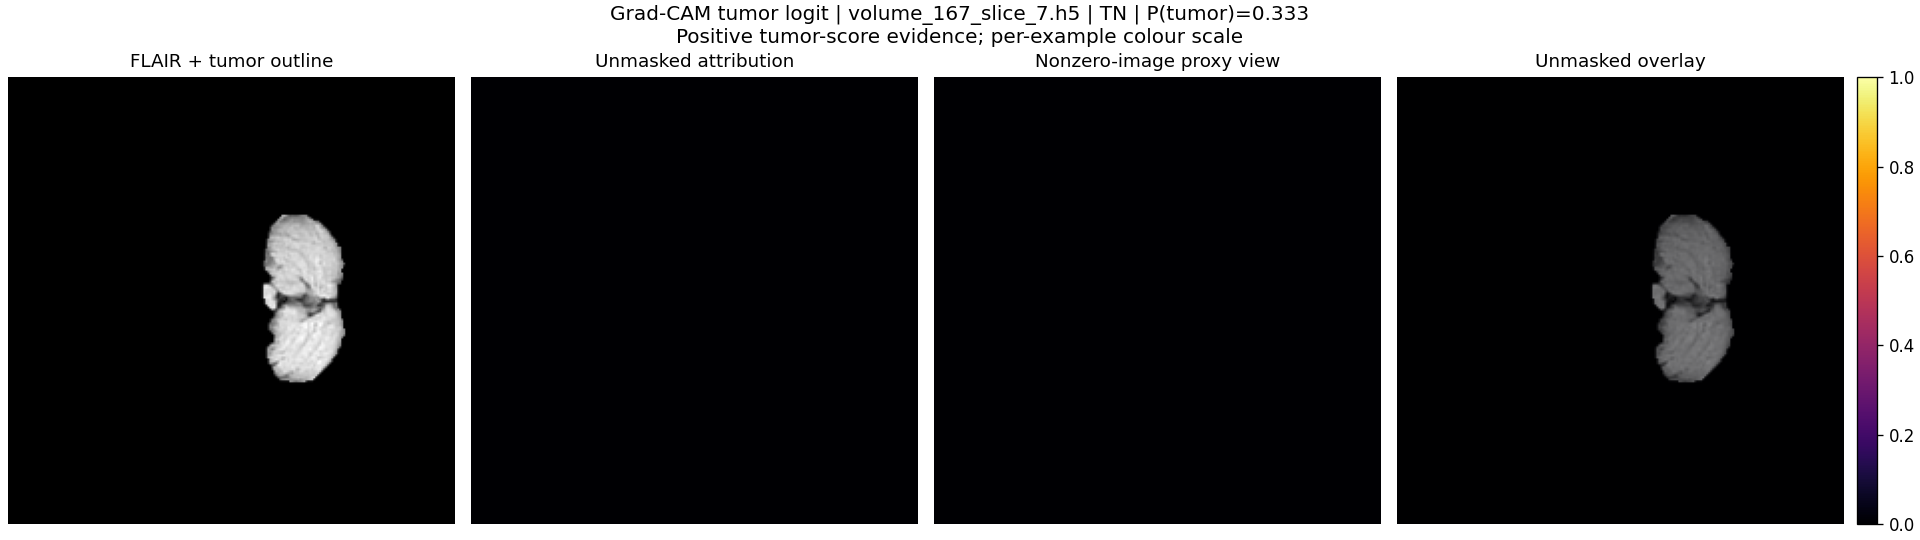

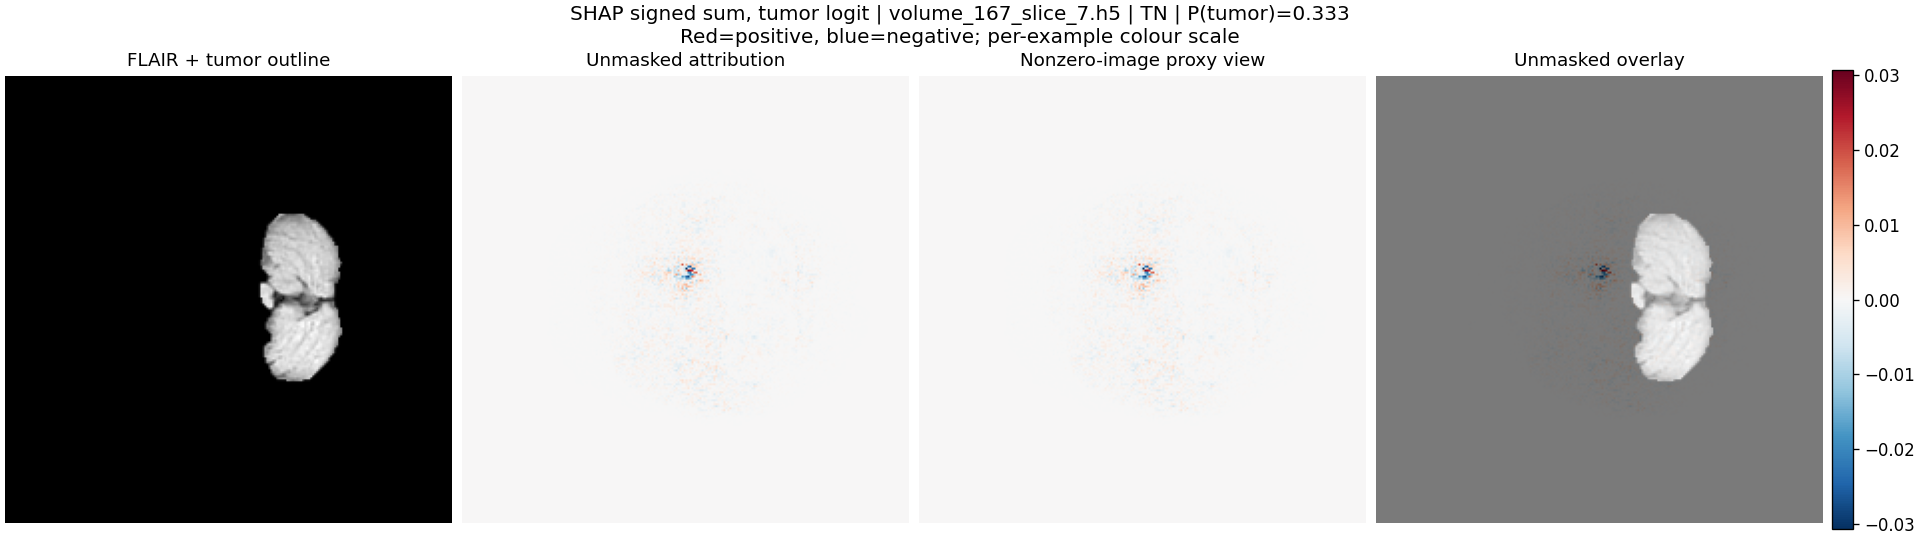

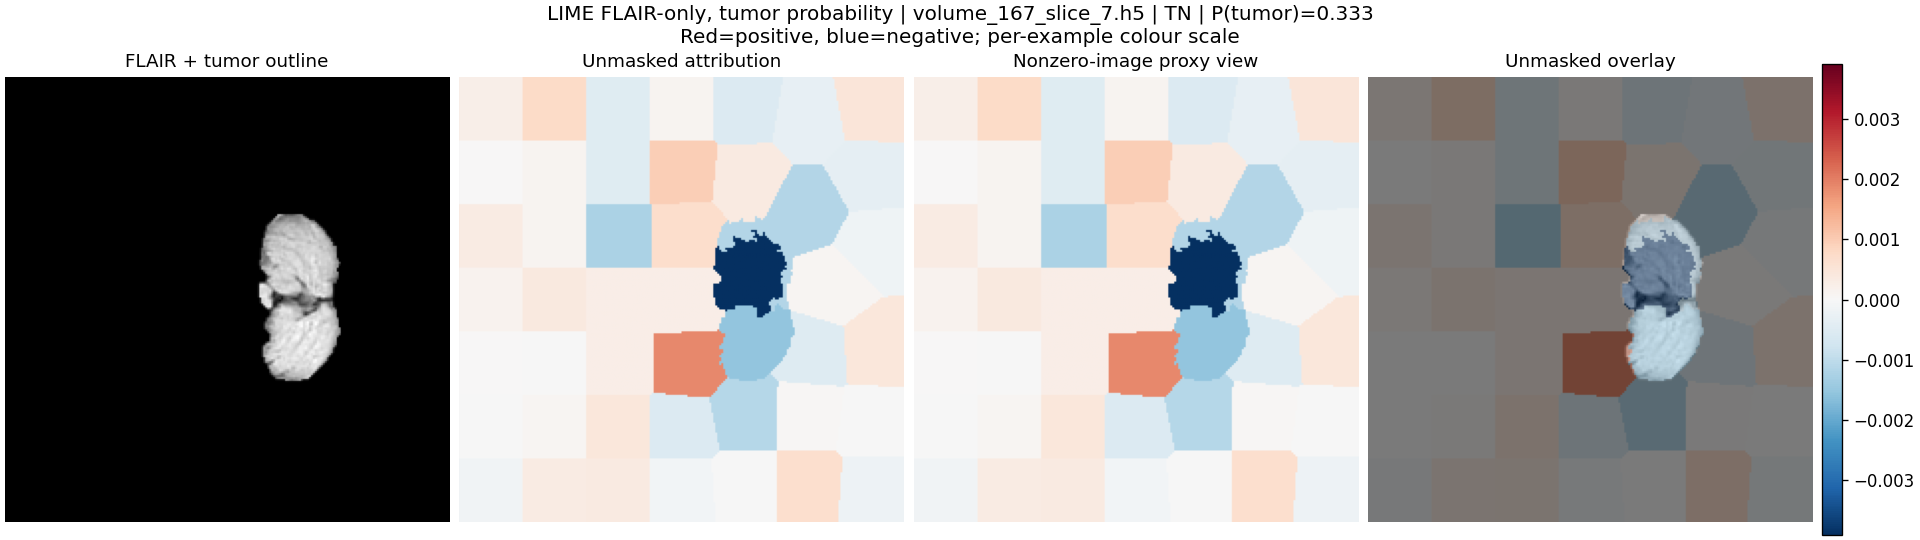

FIGURE_LAYOUT_VERIFIED: 12 figures regenerated from unchanged raw arrays.


In [38]:
from module1_preprocessing import BraTSDataset
from module4_explainability import annotation_masks, write_json

if globals().get('XAI') is None:
    raise RuntimeError('Complete the audited explanations first.')
method_titles = {'gradcam': 'Grad-CAM tumor logit', 'shap': 'SHAP signed sum, tumor logit', 'lime': 'LIME FLAIR-only, tumor probability'}
for record in XAI['selected']:
    filename = record['filename']
    image = BraTSDataset([str(XAI['data_root'] / filename)], augment=False)[0][0].unsqueeze(0)
    brain, tumor = annotation_masks(XAI['data_root'] / filename, image.shape[-1])
    for method, method_title in method_titles.items():
        prefix = Path(filename).stem + '_' + method
        with np.load(XAI['directory'] / method / (prefix + '.npz'), allow_pickle=False) as archive:
            raw = archive['raw']
        if method == 'shap':
            raw = raw.sum(axis=0)
        title = f"{method_title} | {filename} | {record['outcome']} | P(tumor)={record['probability']:.3f}"
        target = XAI['directory'] / method / (prefix + '.png')
        plot_audited_attribution(image, raw, brain, tumor, title, target, signed=method != 'gradcam')
        display(Image(str(target)))
write_json({'layout': 'dedicated_colorbar_axis', 'source': 'existing_raw_npz_arrays', 'inference_repeated': False}, XAI['directory'] / 'figure_layout.json')
print('FIGURE_LAYOUT_VERIFIED: 12 figures regenerated from unchanged raw arrays.')


# Research Scope and Current Evidence

This study tests concept supervision within a three-coordinate bottleneck, not biological causality.
Saved seed-42 results show supervised ROC-AUC 0.9700 versus 0.9494 without concept supervision; accuracy is 0.9158 versus 0.9222.
Concept fidelity fails the constant-reference comparison, so the coordinates must not be presented as reliable clinical region estimates.

Patient identity still needs export-provenance evidence. Multiple matched seeds, a plain-CNN baseline and independent validation remain additional experiments.


## Saved Files in Google Drive

**[Open the organised archive](https://drive.google.com/drive/folders/1yPfSuYVSLd91M-5lJ_z8DNkOkqF_V4Y_)**

All links retain existing Google Drive permissions. No files have been made public.

| Contents | Open |
|---|---|
| Notebook snapshot | [Open folder](https://drive.google.com/drive/folders/1Q2a4NbFc08Zkm10chwtUh1AwOfRJ0Jk1) |
| Python source files | [Open folder](https://drive.google.com/drive/folders/16wfF6CaEV379yvsXw-zSOVvOiqVnz9N_) |
| Numerical test logs | [Open folder](https://drive.google.com/drive/folders/1s-zn02zS5BTWntAVmuka1I37HajgoU8Q) |
| Results and ablation experiments | [Open folder](https://drive.google.com/drive/folders/1vhqAllUdp0o74K7WDdDgQjXxPwUAYhL7) |
| Model checkpoints | [Open folder](https://drive.google.com/drive/folders/1BOKF4soY6F65L1K-S91m-I0xQ87zHv-n) |
| MRI dataset | [Open folder](https://drive.google.com/drive/folders/1M2ADJu4BwA3mJh-UaImQvmUh-h_OGVq7) |
| Package versions and runtime details | [Open folder](https://drive.google.com/drive/folders/18DVAQuuthZA0efopw6i5u4MeQcfSWOqz) |
| Complete file catalog | [Open folder](https://drive.google.com/drive/folders/1UoroeQ-q-bPpaSxm-YNadvHP5BNPm_Dc) |

**[Open saved notebook](https://drive.google.com/file/d/1w6LAuaZcKEue-hZD2rZuRKzIlVDfV7qe/view?usp=drivesdk)** | **[Open test log](https://drive.google.com/file/d/1Be2j2RgavffSOyKiAY8Ob06sj1Jtc9cJ/view?usp=drivesdk)**

Source files, notebook snapshot, test logs and environment records are saved in this archive. Dataset, historical results and checkpoints were already on Drive and remain in their original folders, linked through shortcuts. No training was rerun for archiving.

The dataset folder contains the MRI files; its patient manifest is included in the experiment links below. The file index lists non-dataset project artifacts.

Patient identity remains conditional on the original mapping assertion. Bottleneck coordinates and explanation fidelity are not clinically validated.

### All Saved Project Files

| File | Open |
|---|---|
| 01_Notebook/BrainTumor_T4_Ablation_saved.ipynb | [Open](https://drive.google.com/file/d/1w6LAuaZcKEue-hZD2rZuRKzIlVDfV7qe/view?usp=drivesdk) |
| 02_Source/module1_preprocessing.py | [Open](https://drive.google.com/file/d/1QRwfC_-oz6Z59OOcNhV1epZT191GTDrJ/view?usp=drivesdk) |
| 02_Source/module2_model.py | [Open](https://drive.google.com/file/d/1H-6mDALBXyUjpD5J5DgCAODy-UPjsLYX/view?usp=drivesdk) |
| 02_Source/module3_training.py | [Open](https://drive.google.com/file/d/1tcyGtGtW-dySfem3XPy1qIoako0WxI3I/view?usp=drivesdk) |
| 02_Source/module4_explainability.py | [Open](https://drive.google.com/file/d/1SKAqMs_Xo0sDu5albpS7h5qpDTY0RN9W/view?usp=drivesdk) |
| 02_Source/modules_original | [Open](https://drive.google.com/file/d/17Tffrayt_tAf0wFLsSGRYlR1vz4yq1A9/view?usp=drivesdk) |
| 02_Source/test_reconstructed_modules.py | [Open](https://drive.google.com/file/d/1O1W0tXb45xckGffy_EApQhK3DL66Gv0M/view?usp=drivesdk) |
| 02_Source/verify_checkpoint.py | [Open](https://drive.google.com/file/d/1TxjcmUXWiHc2f3GbOGmJHgCQhYV8CtaA/view?usp=drivesdk) |
| 03_Tests/numerical_test_log.txt | [Open](https://drive.google.com/file/d/1Be2j2RgavffSOyKiAY8Ob06sj1Jtc9cJ/view?usp=drivesdk) |
| 07_Environment/requirements_freeze.txt | [Open](https://drive.google.com/file/d/1mEk9hvTzIDc-SvO7tSQZzj--EGJiTdIG/view?usp=drivesdk) |
| 07_Environment/runtime_environment.json | [Open](https://drive.google.com/file/d/1-1gjLufTJdrnlvENb-bHGsTQO089PbKA/view?usp=drivesdk) |
| ablation_study/stage1_legacy_exploratory/comparison.png | [Open](https://drive.google.com/file/d/1fvhB7EXr6bds0NljsJ937qo9iUGprLLY/view?usp=drivesdk) |
| ablation_study/stage1_legacy_exploratory/legacy_manifest.json | [Open](https://drive.google.com/file/d/1XNe5Q-1NGB7RF-ct4ekBly5uanKAXZBw/view?usp=drivesdk) |
| ablation_study/stage1_legacy_exploratory/metrics.csv | [Open](https://drive.google.com/file/d/1wi7VSpvKVZYg3ehIVhCc_zCJcSEtNPlP/view?usp=drivesdk) |
| ablation_study/stage1_legacy_exploratory/original_concept_errors.csv | [Open](https://drive.google.com/file/d/15uHMFUhrJvlR_BPubIF-MfrHP-81tn76/view?usp=drivesdk) |
| ablation_study/stage1_legacy_exploratory/predictions.csv | [Open](https://drive.google.com/file/d/1DaDo8d-r7-7MJuhSE9lOjH-9knwAS9yM/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/artifact_audit.json | [Open](https://drive.google.com/file/d/1B-aCg8qsiluJWBVD4npSqorrg_NevHPl/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/concept_fidelity.csv | [Open](https://drive.google.com/file/d/1k7NQ3YMFJsj9U2evFtJ1R-7UuO-VkaFx/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/concept_fidelity.png | [Open](https://drive.google.com/file/d/1ZrwgR25z9WFTMuQZ0h33fmMdhj670NS7/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/execution_settings.json | [Open](https://drive.google.com/file/d/1RgdVEYfIshE2vlCfl0quBuzi_NHXnitf/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/figure_layout.json | [Open](https://drive.google.com/file/d/1NGlka6DGkfIOH6-2V-5t2S5UrB1MgquH/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/concept_sensitivity.csv | [Open](https://drive.google.com/file/d/1EyefJf_f_yvnSMoK-HRfJXJx9dNh1r_Y/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/method_settings.json | [Open](https://drive.google.com/file/d/1T-cW5xPjLQTDl6nNu50azhkLYP9rRwJ0/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/spatial_metrics.csv | [Open](https://drive.google.com/file/d/19-3scrTnH_GZiAoukgYBGMN8BEKK4jxY/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/volume_114_slice_62_gradcam.npz | [Open](https://drive.google.com/file/d/1aJPKn4vnlV85H6DEbkPlmki4xVa54Wx_/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/volume_114_slice_62_gradcam.png | [Open](https://drive.google.com/file/d/1b7TPW2EDPz1j9T9EolXUJnAlinbCln_O/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/volume_167_slice_7_gradcam.npz | [Open](https://drive.google.com/file/d/1pRdDx-HSLoXq_Mz3QA7UkFzKlmoEDBbM/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/volume_167_slice_7_gradcam.png | [Open](https://drive.google.com/file/d/1deA1kAgpwgmZ4iRE0OABPxUR7VJxfToE/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/volume_177_slice_35_gradcam.npz | [Open](https://drive.google.com/file/d/1VEQhBa3dIqPlcAatH3eQrjYUKDJ7t8Za/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/volume_177_slice_35_gradcam.png | [Open](https://drive.google.com/file/d/1IvWap3fQjCxawS3ehI49A5uIGBj0GIAG/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/volume_197_slice_55_gradcam.npz | [Open](https://drive.google.com/file/d/1yidr_jS1tjptGzgvYHETT7Cy0XtJFty2/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/gradcam/volume_197_slice_55_gradcam.png | [Open](https://drive.google.com/file/d/1x0AfbyAZQjWEL1rIBGOPd1Tv_NAoVwzr/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/concept_sensitivity.csv | [Open](https://drive.google.com/file/d/1oO2rWuui_276kxPNa67AF9gnd7YhXUJu/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/method_settings.json | [Open](https://drive.google.com/file/d/1aB88dPqCShQXPoYywat3jzmvKXfhT3jp/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/spatial_metrics.csv | [Open](https://drive.google.com/file/d/1zn6j2jfjTjoKmjVdAYd5ZzOF4dlNNO3B/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/volume_114_slice_62_lime.npz | [Open](https://drive.google.com/file/d/1u9nj8_9a0w8C3BhTPSUDclCdDi7IKpMp/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/volume_114_slice_62_lime.png | [Open](https://drive.google.com/file/d/1eDNLUoUlteJPpltq-DvArNf8gs-4DfvA/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/volume_167_slice_7_lime.npz | [Open](https://drive.google.com/file/d/1KyWBRK_vE_n7Pe031vQYkyRCY0eg81jS/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/volume_167_slice_7_lime.png | [Open](https://drive.google.com/file/d/1XhFasXUSd2HIisFiyBGntP_4vibzoaBt/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/volume_177_slice_35_lime.npz | [Open](https://drive.google.com/file/d/1AkqzJApUirlYdXGDjWkB0hdG4_aznxJg/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/volume_177_slice_35_lime.png | [Open](https://drive.google.com/file/d/1mdvY6VanjJvUQ0zJ03mtFSmPkI2ts3kk/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/volume_197_slice_55_lime.npz | [Open](https://drive.google.com/file/d/1loWDVzvo3Gmb_Ps0VizBcsSc8rV6jQ4R/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/lime/volume_197_slice_55_lime.png | [Open](https://drive.google.com/file/d/16CF1NnOuirdJCS3HnvgaRDg8RYP4r4iz/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/provenance.json | [Open](https://drive.google.com/file/d/1GfPpu2Bw58dpkjxmrSlwq6j72i02deyl/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/reviewed_study_dashboard.png | [Open](https://drive.google.com/file/d/1E7vqrm1Wu-ByfdkhL3eJ0kPZpfKG595a/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/selected_cases.csv | [Open](https://drive.google.com/file/d/1yfPA22yFM33hiJvYMhBNXkzgsXvu2Jza/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/concept_sensitivity.csv | [Open](https://drive.google.com/file/d/1B-At-GnH4JxTFgNUYHLj3vLxoOkvGNmu/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/method_settings.json | [Open](https://drive.google.com/file/d/1PHm13o_XRAREUK_VmgfnZratrFLu_lb0/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/spatial_metrics.csv | [Open](https://drive.google.com/file/d/1v8zxhz0e9oDu-Y4TRFVrUJZBRdYvdO_F/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/volume_114_slice_62_shap.npz | [Open](https://drive.google.com/file/d/1NEYmEUZrooKM5sWNXuE3cJzz9R_uNA6D/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/volume_114_slice_62_shap.png | [Open](https://drive.google.com/file/d/19YkeDIlNM2TGiJFrh2exHcdClSgN6wfd/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/volume_167_slice_7_shap.npz | [Open](https://drive.google.com/file/d/1w61gBQhcLINQ9fKX2cwOtEnUEGXjMyzV/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/volume_167_slice_7_shap.png | [Open](https://drive.google.com/file/d/1oLUxjgQDI9AZuWz35KvJOft1JEu6WKd6/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/volume_177_slice_35_shap.npz | [Open](https://drive.google.com/file/d/1ruqTu1qy7tWsvj8w2dQac2oUK1XGZdRC/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/volume_177_slice_35_shap.png | [Open](https://drive.google.com/file/d/1Ne6YnrH3wTZKSKoWX3U62JP7rV9n52YA/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/volume_197_slice_55_shap.npz | [Open](https://drive.google.com/file/d/1z_zc-i918h_c4RcQfCKcGL1eBy2DaD9u/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/shap/volume_197_slice_55_shap.png | [Open](https://drive.google.com/file/d/1oMvCUJfDDpzIf6pWYGlW31bv3pAqd4X6/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/test_predictions.csv | [Open](https://drive.google.com/file/d/1By6xj3z-vFGeId0-Vlw2uZVrHGsbT8uN/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z/training_background.csv | [Open](https://drive.google.com/file/d/1AS2zpu7Cme1xxwJPdDkRkfNxkUgJ7_-7/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/concept_comparison.csv | [Open](https://drive.google.com/file/d/1VRYil9aOvjC9is9Sc8qx-tq3NOkKzpnW/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/config.json | [Open](https://drive.google.com/file/d/1slMRkxReJv8Zu7C2FJsxPijgT538B-K8/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/patient_bootstrap_ci.csv | [Open](https://drive.google.com/file/d/16ViEv-7dDuYQRJJgCIJTU-LFP5eukSJg/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/patient_split.csv | [Open](https://drive.google.com/file/d/1sOHFVYkS7UhDZpNlaDnPrrQfbIIWv6zZ/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/shared_pretrained_initialization.pth | [Open](https://drive.google.com/file/d/1WLnPgp2x6lAz03NBhWsEWR_77a7elrd7/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/supervised_lambda1/best.pth | [Open](https://drive.google.com/file/d/1T4ld7TkbZKtgLkw4WvLtFoD9T5XLzCrk/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/supervised_lambda1/history.csv | [Open](https://drive.google.com/file/d/1RMggvbh8vgagxsxlB4-iRGIOqynDUSEI/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/supervised_lambda1/resume.pth | [Open](https://drive.google.com/file/d/18fkHKRrilmm6xciAgKlUhfRMHe7uqyyu/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/supervised_lambda1/test_predictions.csv | [Open](https://drive.google.com/file/d/1JuJ3MyJS5Q03xBQma-wF6zJgucgr2xZx/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/test_comparison.csv | [Open](https://drive.google.com/file/d/1wPJo-OCREJ1NvHChAPaRe0TxMBQEiqCR/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/test_comparison.png | [Open](https://drive.google.com/file/d/1JBENMU_sfVui_Nui5dz_uq_Achh3uHT7/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/training_target_audit.json | [Open](https://drive.google.com/file/d/1guZ9M6HDINp5f6gv9tseJS_iLHlUof7N/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/unsupervised_lambda0/best.pth | [Open](https://drive.google.com/file/d/1ZT3KJ-Q9Z92vhpO5Kw6qHH2D5JBJ0MgP/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/unsupervised_lambda0/history.csv | [Open](https://drive.google.com/file/d/1EMOZfmoVKrIW3OU91fqK0vlpQH3wIqk0/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/unsupervised_lambda0/resume.pth | [Open](https://drive.google.com/file/d/1z4TCezfRgZ0ZwfNEDg8NdSQbhc2yzO6X/view?usp=drivesdk) |
| ablation_study/stage2_seed42_2f00b2b02fd1/unsupervised_lambda0/test_predictions.csv | [Open](https://drive.google.com/file/d/1WLknVGqbW3ZtuPCI49fkppbqNje-a6Aj/view?usp=drivesdk) |
| checkpoints/best_densenet121.pth | [Open](https://drive.google.com/file/d/14OMFDUwiB-jdY9f3UXmOwadAyTgpxCU6/view?usp=drivesdk) |
| checkpoints/best_resnet50.pth | [Open](https://drive.google.com/file/d/122lNUAyIviEDPyUxKktjWSxj7SLUaEbB/view?usp=drivesdk) |
| checkpoints/best_resnext50.pth | [Open](https://drive.google.com/file/d/18C_8R7x9892I1ddN_soPUvEAAMn90p0F/view?usp=drivesdk) |
| checkpoints/resume_densenet121.pth | [Open](https://drive.google.com/file/d/13YfFss99Cq0L4viS4D4qFLg4DDw7FILf/view?usp=drivesdk) |
| checkpoints/resume_resnet50.pth | [Open](https://drive.google.com/file/d/1kJutKgiU-yUJoFlfDR9d7Zn44c-NEU5d/view?usp=drivesdk) |
| checkpoints/resume_resnext50.pth | [Open](https://drive.google.com/file/d/1-YdYIDrEfIsJIDqov9XlbXsyuyPRjSjh/view?usp=drivesdk) |
| modules/module1_preprocessing.py | [Open](https://drive.google.com/file/d/1-VSKPnSIUaEqhgds5Jq30U5KBWvGZJpF/view?usp=drivesdk) |
| modules/module2_model.py | [Open](https://drive.google.com/file/d/12qoJDxIUGUVhykgLsp7f6J3WyC4RlVbj/view?usp=drivesdk) |
| modules/module3_training.py | [Open](https://drive.google.com/file/d/1VQVR7FTLx94EBRFiHce2YSi8VVtKn0Xj/view?usp=drivesdk) |
| modules/module4_counterfactual.py | [Open](https://drive.google.com/file/d/1tIrhDs_16G-4E6giMyWn37l5yVaw_TeX/view?usp=drivesdk) |
| modules/verify_checkpoint.py | [Open](https://drive.google.com/file/d/11Fc_luzO5XlOlGKc8klG0HOxCrPDftyH/view?usp=drivesdk) |
| results/counterfactual_sample_0.png | [Open](https://drive.google.com/file/d/1qoIV4BbSmKmM0u7m5TDRBgm0kL47ZDEK/view?usp=drivesdk) |
| results/counterfactual_sample_1.png | [Open](https://drive.google.com/file/d/1IQx1aGm_6p9IUfP_TTFr4OIVrfxoSkUr/view?usp=drivesdk) |
| results/counterfactual_sample_2.png | [Open](https://drive.google.com/file/d/1BmwcalYdI-wuLPBFBedrwGACRNT2ZsJO/view?usp=drivesdk) |
| results/curves_densenet121.png | [Open](https://drive.google.com/file/d/1qwgu0d9IHApdZSAe5R_Q812KwJkHa76T/view?usp=drivesdk) |
| results/curves_resnet50.png | [Open](https://drive.google.com/file/d/1f37ClKvr1BcVsVu6-HqCTIiuaURq70WV/view?usp=drivesdk) |
| results/curves_resnext50.png | [Open](https://drive.google.com/file/d/1-Z2Iid9Whb5qm6288tHkqtzWR3wy8fqe/view?usp=drivesdk) |
| results/full_evaluation_dashboard.png | [Open](https://drive.google.com/file/d/1Hlxn34y3decfAM_EH3WbQ94DdKCwsfiE/view?usp=drivesdk) |
| results/gradcam_10samples_comparison.png | [Open](https://drive.google.com/file/d/1dnLlY8HaGM1_HBq1OycFDKPeZVSvhXjJ/view?usp=drivesdk) |
| results/gradcam_brain_shape_final.png | [Open](https://drive.google.com/file/d/1m3A_4q37tXjp8OsbvY9iHz_6XwEOHUtq/view?usp=drivesdk) |
| results/gradcam_fullbrain_final.png | [Open](https://drive.google.com/file/d/1Z-srfBN7CGzEAE-OHsuEsaTcTdaQbAYA/view?usp=drivesdk) |
| results/gradcam_fullbrain_labeled.png | [Open](https://drive.google.com/file/d/1E3emIT7WxoMj70fY0CK3Mr_Izml1TiQ_/view?usp=drivesdk) |
| results/gradcam_masked_0.png | [Open](https://drive.google.com/file/d/1HD1Xa-30Q6pkOXZa9fovD-5A8cOgfiUv/view?usp=drivesdk) |
| results/gradcam_masked_1.png | [Open](https://drive.google.com/file/d/1gOVXX0PaoXGU4JV3YLWOHL-34VK-TrJk/view?usp=drivesdk) |
| results/gradcam_masked_10.png | [Open](https://drive.google.com/file/d/1j1v5ZhiYz7QAdG3svO6GJlkq9_f1xUjs/view?usp=drivesdk) |
| results/gradcam_masked_11.png | [Open](https://drive.google.com/file/d/1yft9T27M0pzvCII0VcdPGKx5x11mMTYz/view?usp=drivesdk) |
| results/gradcam_masked_12.png | [Open](https://drive.google.com/file/d/1_d6-z_HAIUCOf3PztaU893972gfINS_d/view?usp=drivesdk) |
| results/gradcam_masked_13.png | [Open](https://drive.google.com/file/d/1MgK81m4U7TFXJBi3b_gHCj7vS9RoPbnp/view?usp=drivesdk) |
| results/gradcam_masked_14.png | [Open](https://drive.google.com/file/d/17AOtIk4r_qbTvVKEy4HVPDd9EUSCnZnU/view?usp=drivesdk) |
| results/gradcam_masked_15.png | [Open](https://drive.google.com/file/d/1i8Grj3HtVtWXwcKwChal5bo_Pg_982or/view?usp=drivesdk) |
| results/gradcam_masked_16.png | [Open](https://drive.google.com/file/d/1uVDU8lixW6wXR1Oy7ttKEh3yqUGTkB0j/view?usp=drivesdk) |
| results/gradcam_masked_2.png | [Open](https://drive.google.com/file/d/1rSWTCmKrUHM4eTgq0dXbRqKgvIpoqdga/view?usp=drivesdk) |
| results/gradcam_masked_3.png | [Open](https://drive.google.com/file/d/1nPfZBKXIXMFuvyUt-UAhXrwmsAP-aptb/view?usp=drivesdk) |
| results/gradcam_masked_4.png | [Open](https://drive.google.com/file/d/1M1PX0Q6bZEgwHzmaVI_UV_IGwB73o5MP/view?usp=drivesdk) |
| results/gradcam_masked_5.png | [Open](https://drive.google.com/file/d/1l-DJtiz4tyv0kQR5qakthg3-frAs0kZB/view?usp=drivesdk) |
| results/gradcam_masked_6.png | [Open](https://drive.google.com/file/d/1xyN7vNi0mm7D_JmnJB5NlsDmJ-3TGzXk/view?usp=drivesdk) |
| results/gradcam_masked_7.png | [Open](https://drive.google.com/file/d/18mFQ42L8wSKEXZu92jHR10-vglr-tCDq/view?usp=drivesdk) |
| results/gradcam_masked_8.png | [Open](https://drive.google.com/file/d/1h81E9Yxd9Jdx_GCHGqmEksyn7tYxq9_5/view?usp=drivesdk) |
| results/gradcam_masked_9.png | [Open](https://drive.google.com/file/d/1oXXYK1he4-PCmoyRz2mNbS-GzVLfgipD/view?usp=drivesdk) |
| results/gradcam_sample_0.png | [Open](https://drive.google.com/file/d/1n4jb8vIABBsD87zK1UoHzBHdqA2-T0mG/view?usp=drivesdk) |
| results/gradcam_sample_1.png | [Open](https://drive.google.com/file/d/1uPhloGXHCCwbwAw5YHi3wpHnGyohGijB/view?usp=drivesdk) |
| results/gradcam_sample_2.png | [Open](https://drive.google.com/file/d/1xT-gZcJcnkL3bDqnD6W1KTixqsKMQguy/view?usp=drivesdk) |
| results/gradcam_sample_3.png | [Open](https://drive.google.com/file/d/1p_no2E9ikrfn-7zC1UhafX9EblM1Hvv9/view?usp=drivesdk) |
| results/gradcam_sample_4.png | [Open](https://drive.google.com/file/d/1__x5Rtwl17RpjoCtnwgjDLRsmTv109_N/view?usp=drivesdk) |
| results/gradcam_tumor_vs_notumor.png | [Open](https://drive.google.com/file/d/1AF9m82MCrEztNddFxPQZeUSXqEBd0-Yv/view?usp=drivesdk) |
| results/gradcam_v2_sample_0.png | [Open](https://drive.google.com/file/d/1x2e3dYrC6d1ic1aoxZXf4ux_1ToURqsD/view?usp=drivesdk) |
| results/gradcam_v2_sample_1.png | [Open](https://drive.google.com/file/d/13jaa_ywEa-eN_LmihN35RLmaY9V9oRPB/view?usp=drivesdk) |
| results/gradcam_v2_sample_10.png | [Open](https://drive.google.com/file/d/1FWQje6Qx5HU9mFxH4z3xmBhEwjtiQGlh/view?usp=drivesdk) |
| results/gradcam_v2_sample_11.png | [Open](https://drive.google.com/file/d/1uhgOye_nFzPF1uwJXWu8LdVaoIMbLIvv/view?usp=drivesdk) |
| results/gradcam_v2_sample_12.png | [Open](https://drive.google.com/file/d/1uJetHqXp1FrhwukwbYuNRhoXVVcqSrC4/view?usp=drivesdk) |
| results/gradcam_v2_sample_13.png | [Open](https://drive.google.com/file/d/13dYtzkrP5lbtRNrIFz0x-igSRWKvtZme/view?usp=drivesdk) |
| results/gradcam_v2_sample_14.png | [Open](https://drive.google.com/file/d/1t0PvEZ0MxZCgP1OpUA-GdhAs8Z7IR1Tg/view?usp=drivesdk) |
| results/gradcam_v2_sample_15.png | [Open](https://drive.google.com/file/d/1XZ15BcC-KWiHeyqiQHB3__4hVNiOR0RE/view?usp=drivesdk) |
| results/gradcam_v2_sample_16.png | [Open](https://drive.google.com/file/d/1YWrB-5QIomhoC7ST0B94tZY_MnqakQHE/view?usp=drivesdk) |
| results/gradcam_v2_sample_2.png | [Open](https://drive.google.com/file/d/1Or0iHQ-Apw6VJailymtgjHWiIcxeW7s8/view?usp=drivesdk) |
| results/gradcam_v2_sample_3.png | [Open](https://drive.google.com/file/d/1HrwVCBBAy0-aAylPQbeEX3txMpmLg2fV/view?usp=drivesdk) |
| results/gradcam_v2_sample_4.png | [Open](https://drive.google.com/file/d/15dVBXBjLQdFJ_Q9KxzlbfBxlyY4ttF2K/view?usp=drivesdk) |
| results/gradcam_v2_sample_5.png | [Open](https://drive.google.com/file/d/1jBXbGlsTuLyAd8-tgSHFzRAMGu25oFT0/view?usp=drivesdk) |
| results/gradcam_v2_sample_6.png | [Open](https://drive.google.com/file/d/1C8uQmIvTAnaQlE56MXzEMnJ_f--Jg9OI/view?usp=drivesdk) |
| results/gradcam_v2_sample_7.png | [Open](https://drive.google.com/file/d/1gY-ZCNZg2KTbdsonHazow2YCZHaae8EM/view?usp=drivesdk) |
| results/gradcam_v2_sample_8.png | [Open](https://drive.google.com/file/d/1UVTYwqk7GfkIq5cN_d5W2R_eBEVVmTy0/view?usp=drivesdk) |
| results/gradcam_v2_sample_9.png | [Open](https://drive.google.com/file/d/1mvr8qhxcGyk-czvoixQ15XAraD1YtVo6/view?usp=drivesdk) |
| results/lime_brain_shape_final.png | [Open](https://drive.google.com/file/d/1aHDIKGuiqzlpbjMSxGdcurXeH9G0FIrx/view?usp=drivesdk) |
| results/lime_sample_0.png | [Open](https://drive.google.com/file/d/18LOQmVf2rkzSZeJGme_zbXYg__5pnaEK/view?usp=drivesdk) |
| results/lime_sample_1.png | [Open](https://drive.google.com/file/d/1feffnCdj2XRTOTxKHLRrM7O-pcmqfkhM/view?usp=drivesdk) |
| results/lime_sample_2.png | [Open](https://drive.google.com/file/d/1yXwPKa_LQMdOnoPxytl_1ThVpKC5Y9Mh/view?usp=drivesdk) |
| results/sample_check.png | [Open](https://drive.google.com/file/d/1GGuZ8nTBjcPGNfLcgREGlq2JF_GshH-D/view?usp=drivesdk) |
| results/sensitivity_summary_resnet50.png | [Open](https://drive.google.com/file/d/1Ms1B8PdtO-R2eBwLQlW6ZRgu7k1EaPvv/view?usp=drivesdk) |
| results/shap_10samples.png | [Open](https://drive.google.com/file/d/1yhJ3B5wkSVOgTSiUMpqvcn314jTGJ1uP/view?usp=drivesdk) |
| results/shap_explanation.png | [Open](https://drive.google.com/file/d/1ln74VYuNwqxcKJ0LSSUvebAzEG7qPQM9/view?usp=drivesdk) |


## Save and Refresh the Drive Archive

This cell saves source files, test logs and environment records, and indexes existing Drive outputs. Large existing datasets and checkpoints are linked through shortcuts without duplication. Run the final snapshot/index cell after saving notebook changes to refresh the archived notebook.


In [41]:
from pathlib import Path
from datetime import datetime, timezone
import contextlib, hashlib, io, json, platform, subprocess, sys, unittest
import torch
from google.colab import auth
import google.auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseUpload
from IPython.display import Markdown, display

auth.authenticate_user()
archive_credentials, _ = google.auth.default()
archive_drive = build('drive', 'v3', credentials=archive_credentials, cache_discovery=False)
ARCHIVE_PROJECT_ID = '1fc9nMNHLoR8yxleU9Kr2Y2XiHhWTrEnC'
ARCHIVE_NOTEBOOK_ID = '1TJYgNEYmlrxorbhc7pe1OExLo89Xixr1'
ARCHIVE_FOLDER_MIME = 'application/vnd.google-apps.folder'
ARCHIVE_FIELDS = 'id,name,mimeType,size,md5Checksum,webViewLink,shortcutDetails'

def archive_children(parent):
    found, token = [], None
    while True:
        response = archive_drive.files().list(q=f"'{parent}' in parents and trashed=false", fields=f'nextPageToken,files({ARCHIVE_FIELDS})', pageSize=1000, pageToken=token).execute()
        found.extend(response.get('files', []))
        token = response.get('nextPageToken')
        if not token:
            return found

def archive_url(item):
    return item.get('webViewLink') or ('https://drive.google.com/drive/folders/' if item['mimeType'] == ARCHIVE_FOLDER_MIME else 'https://drive.google.com/file/d/') + item['id'] + ('' if item['mimeType'] == ARCHIVE_FOLDER_MIME else '/view')

def archive_folder(parent, name):
    existing = [item for item in archive_children(parent) if item['name'] == name]
    if existing:
        if len(existing) != 1 or existing[0]['mimeType'] != ARCHIVE_FOLDER_MIME:
            raise RuntimeError('Ambiguous archive folder: ' + name)
        return existing[0]
    return archive_drive.files().create(body={'name': name, 'mimeType': ARCHIVE_FOLDER_MIME, 'parents': [parent]}, fields=ARCHIVE_FIELDS).execute()

def archive_upload(parent, name, data, mime='text/plain'):
    data = data.encode('utf-8') if isinstance(data, str) else data
    existing = [item for item in archive_children(parent) if item['name'] == name]
    if len(existing) > 1:
        raise RuntimeError('Duplicate archive file: ' + name)
    media = MediaIoBaseUpload(io.BytesIO(data), mimetype=mime, resumable=False)
    if existing:
        item = archive_drive.files().update(fileId=existing[0]['id'], media_body=media, fields=ARCHIVE_FIELDS).execute()
    else:
        item = archive_drive.files().create(body={'name': name, 'parents': [parent]}, media_body=media, fields=ARCHIVE_FIELDS).execute()
    if item.get('md5Checksum') != hashlib.md5(data).hexdigest():
        raise RuntimeError('Uploaded content checksum mismatch: ' + name)
    return item

def archive_shortcut(parent, name, target):
    existing = [item for item in archive_children(parent) if item['name'] == name]
    if existing:
        if len(existing) != 1 or existing[0].get('shortcutDetails', {}).get('targetId') != target['id']:
            raise RuntimeError('Shortcut target mismatch: ' + name)
        return existing[0]
    return archive_drive.files().create(body={'name': name, 'mimeType': 'application/vnd.google-apps.shortcut', 'parents': [parent], 'shortcutDetails': {'targetId': target['id']}}, fields=ARCHIVE_FIELDS).execute()

def archive_walk(parent, prefix):
    rows = []
    for item in archive_children(parent):
        path = prefix + '/' + item['name']
        if item['mimeType'] == ARCHIVE_FOLDER_MIME:
            rows.extend(archive_walk(item['id'], path))
        else:
            rows.append({'path': path, 'id': item['id'], 'url': archive_url(item), 'bytes': item.get('size'), 'md5': item.get('md5Checksum'), 'storage': 'already_on_drive'})
    return rows

if 'ARCHIVE_STATE' not in globals():
    archive_name = 'Submission_Archive_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    ARCHIVE_STATE = {'root': archive_folder(ARCHIVE_PROJECT_ID, archive_name)}
archive_root_id = ARCHIVE_STATE['root']['id']
archive_folders = {name: archive_folder(archive_root_id, name) for name in ['01_Notebook', '02_Source', '03_Tests', '04_Results', '05_Checkpoints', '06_Dataset', '07_Environment', '08_Index']}
ARCHIVE_STATE['folders'] = archive_folders
project_folders = {item['name']: item for item in archive_children(ARCHIVE_PROJECT_ID) if item['mimeType'] == ARCHIVE_FOLDER_MIME and item['name'] in ['dataset', 'checkpoints', 'results', 'ablation_study', 'modules']}
for original, category in [('dataset', '06_Dataset'), ('checkpoints', '05_Checkpoints'), ('results', '04_Results'), ('ablation_study', '04_Results'), ('modules', '02_Source')]:
    if original in project_folders:
        archive_shortcut(archive_folders[category]['id'], original + '_original', project_folders[original])
source_names = ['module1_preprocessing.py', 'module2_model.py', 'module3_training.py', 'module4_explainability.py', 'test_reconstructed_modules.py', 'verify_checkpoint.py']
ARCHIVE_STATE['sources'] = [archive_upload(archive_folders['02_Source']['id'], name, (Path('/content') / name).read_bytes(), 'text/x-python') for name in source_names]
print('ARCHIVE_SOURCES_SAVED', len(ARCHIVE_STATE['sources']), flush=True)

import test_reconstructed_modules
suite = unittest.defaultTestLoader.loadTestsFromModule(test_reconstructed_modules)
test_stream = io.StringIO()
previous_threads = torch.get_num_threads()
try:
    torch.set_num_threads(2)
    with contextlib.redirect_stdout(test_stream), contextlib.redirect_stderr(test_stream):
        archive_test_result = unittest.TextTestRunner(stream=test_stream, verbosity=2).run(suite)
finally:
    torch.set_num_threads(previous_threads)
ARCHIVE_STATE['tests'] = archive_upload(archive_folders['03_Tests']['id'], 'numerical_test_log.txt', test_stream.getvalue())
ARCHIVE_STATE['test_summary'] = {'run': archive_test_result.testsRun, 'skipped': len(archive_test_result.skipped), 'successful': archive_test_result.wasSuccessful()}
print('ARCHIVE_TESTS', json.dumps(ARCHIVE_STATE['test_summary']), flush=True)
freeze = subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True, check=True).stdout
archive_upload(archive_folders['07_Environment']['id'], 'requirements_freeze.txt', freeze)
environment = {'python': sys.version, 'platform': platform.platform(), 'torch': torch.__version__, 'cuda_available': torch.cuda.is_available(), 'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None, 'source_sha256': {name: hashlib.sha256((Path('/content') / name).read_bytes()).hexdigest() for name in source_names}, 'tests': ARCHIVE_STATE['test_summary']}
archive_upload(archive_folders['07_Environment']['id'], 'runtime_environment.json', json.dumps(environment, indent=2), 'application/json')
ARCHIVE_INDEX_ROWS = []
for name in ['results', 'checkpoints', 'ablation_study', 'modules']:
    if name in project_folders:
        ARCHIVE_INDEX_ROWS.extend(archive_walk(project_folders[name]['id'], name))
for category in ['02_Source', '03_Tests', '07_Environment']:
    ARCHIVE_INDEX_ROWS.extend(archive_walk(archive_folders[category]['id'], category))
ARCHIVE_STATE['catalog'] = archive_upload(archive_folders['08_Index']['id'], 'file_catalog.json', json.dumps(ARCHIVE_INDEX_ROWS, indent=2), 'application/json')
ARCHIVE_LINKS = {'Archive': archive_url(ARCHIVE_STATE['root']), **{name: archive_url(item) for name, item in archive_folders.items()}, **{name: archive_url(item) for name, item in project_folders.items()}}
print('ARCHIVE_LINKS_JSON=' + json.dumps(ARCHIVE_LINKS), flush=True)
print('ARCHIVE_CATALOG_COUNT', len(ARCHIVE_INDEX_ROWS), flush=True)
print('ARCHIVE_READY_FOR_NOTEBOOK_SNAPSHOT')
if not archive_test_result.wasSuccessful():
    raise RuntimeError('Test failures were preserved in the saved test log; inspect before publication.')


ARCHIVE_SOURCES_SAVED 6


  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

ARCHIVE_TESTS {"run": 20, "skipped": 3, "successful": true}
ARCHIVE_LINKS_JSON={"Archive": "https://drive.google.com/drive/folders/1yPfSuYVSLd91M-5lJ_z8DNkOkqF_V4Y_", "01_Notebook": "https://drive.google.com/drive/folders/1Q2a4NbFc08Zkm10chwtUh1AwOfRJ0Jk1", "02_Source": "https://drive.google.com/drive/folders/16wfF6CaEV379yvsXw-zSOVvOiqVnz9N_", "03_Tests": "https://drive.google.com/drive/folders/1s-zn02zS5BTWntAVmuka1I37HajgoU8Q", "04_Results": "https://drive.google.com/drive/folders/1vhqAllUdp0o74K7WDdDgQjXxPwUAYhL7", "05_Checkpoints": "https://drive.google.com/drive/folders/1BOKF4soY6F65L1K-S91m-I0xQ87zHv-n", "06_Dataset": "https://drive.google.com/drive/folders/1M2ADJu4BwA3mJh-UaImQvmUh-h_OGVq7", "07_Environment": "https://drive.google.com/drive/folders/18DVAQuuthZA0efopw6i5u4MeQcfSWOqz", "08_Index": "https://drive.google.com/drive/folders/1UoroeQ-q-bPpaSxm-YNadvHP5BNPm_Dc", "modules": "https://drive.google.com/drive/folders/1G1-RU5JE0UJmdxjQzD219_wE6wA8HmhG", "ablation_study": "htt

In [ ]:
import sys
import os
import gc
import re
import json
import random
import hashlib
import time
import importlib.util
import subprocess
import shutil
from pathlib import Path

# Clean up any duplicate duplicate uploads if they exist
for dup in Path('/content').glob('module* (*).py'):
    try:
        dup.unlink()
    except Exception:
        pass

from google.colab import drive, files as colab_files
try:
    drive.mount('/content/drive')
except Exception as e:
    print(f"⚠️ Google Drive mount failed: {e}")
    print("Please ensure you are running this in an interactive Colab session and have authorized Drive access.")

abl_packages = {'h5py': 'h5py', 'cv2': 'opencv-python-headless',
                'sklearn': 'scikit-learn', 'pandas': 'pandas', 'matplotlib': 'matplotlib'}
abl_missing = [package for module, package in abl_packages.items()
               if importlib.util.find_spec(module) is None]
if abl_missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *abl_missing])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
                             f1_score, confusion_matrix)
from IPython.display import display

ABL_ROOT = Path('/content/drive/MyDrive/BraTS2020')
ABL_DATA = ABL_ROOT / 'dataset/BraTS2020_training_data/content/data'
ABL_CHECKPOINT = ABL_ROOT / 'checkpoints/best_resnet50.pth'
ABL_OUTPUT = ABL_ROOT / 'ablation_study'
ABL_MODULE_DIR = Path('/content')
ABL_BATCH = 8
ABL_SEED = 42
ABL_CONCEPT_NAMES = ['edema', 'enhancing', 'necrotic']
ABL_CONCEPT_ORDER_CONFIRMED = False

os.chdir('/content')
sys.path.insert(0, str(ABL_MODULE_DIR))
abl_required = ['module1_preprocessing.py', 'module2_model.py']

# Try to automatically copy the modules from Google Drive first
for name in abl_required:
    dest_file = ABL_MODULE_DIR / name
    if not dest_file.is_file():
        # Search in the main workspace directory on Drive where they were uploaded previously
        src_file = Path('/content/drive/MyDrive') / name
        if not src_file.is_file():
            src_file = ABL_ROOT / name
        if src_file.is_file():
            shutil.copy(src_file, dest_file)
            print(f"✅ Automatically copied {name} from Drive to {ABL_MODULE_DIR}")

# If still missing, prompt for manual upload
if not all((ABL_MODULE_DIR / name).is_file() for name in abl_required):
    print('Upload the ORIGINAL preprocessing and model Python modules, plus any dependencies.')
    colab_files.upload()

# Look for (1) files and replace main files if user uploaded duplicates
for orig_name in abl_required:
    dup_file = ABL_MODULE_DIR / orig_name.replace('.py', ' (1).py')
    if dup_file.is_file():
        shutil.move(dup_file, ABL_MODULE_DIR / orig_name)
        print(f"🔄 Replaced {orig_name} with freshly uploaded duplicate version.")

if not all((ABL_MODULE_DIR / name).is_file() for name in abl_required):
    raise FileNotFoundError('Both original Python modules are required in /content.')

# Force reload the modules
if 'module1_preprocessing' in sys.modules:
    importlib.reload(sys.modules['module1_preprocessing'])
if 'module2_model' in sys.modules:
    importlib.reload(sys.modules['module2_model'])

from module1_preprocessing import BraTSDataset, Config
from module2_model import ConceptBrainTumorModel, ConceptBCELoss

if not torch.cuda.is_available():
    raise RuntimeError('In Colab select Runtime > Change runtime type > T4 GPU.')
ABL_DEVICE = torch.device('cuda')
print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__)
print('Checkpoint:', ABL_CHECKPOINT)
if not ABL_DATA.is_dir() or not ABL_CHECKPOINT.is_file():
    print('⚠️ WARNING: ABL_DATA or ABL_CHECKPOINT was not found. Please verify your Google Drive paths.')
else:
    Config.DATA_PATH = str(ABL_DATA)
Config.BATCH_SIZE = ABL_BATCH
Config.NUM_WORKERS = 0
ABL_OUTPUT.mkdir(parents=True, exist_ok=True)

def abl_load_trusted(path):
    return torch.load(path, map_location='cpu', weights_only=False)

def abl_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def abl_loader(paths, training=False):
    return DataLoader(BraTSDataset([str(path) for path in paths], augment=training),
                      batch_size=ABL_BATCH, shuffle=training, num_workers=0,
                      pin_memory=True, drop_last=False)

def abl_save_json(value, path):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False))
    os.replace(temporary, path)

def abl_save_checkpoint(value, path):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    torch.save(value, temporary)
    os.replace(temporary, path)

def abl_metrics(labels, probabilities):
    labels = np.asarray(labels, dtype=int).reshape(-1)
    probabilities = np.asarray(probabilities, dtype=float).reshape(-1)
    if labels.size == 0 or labels.shape != probabilities.shape:
        raise ValueError('Empty or mismatched predictions.')
    if not np.isfinite(probabilities).all() or not np.isin(labels, [0, 1]).all():
        raise ValueError('Invalid binary classification inputs.')
    predictions = probabilities >= 0.5
    tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=[0, 1]).ravel()
    both_classes = np.unique(labels).size == 2
    return dict(accuracy=float(accuracy_score(labels, predictions)),
                roc_auc=float(roc_auc_score(labels, probabilities)) if both_classes else None,
                pr_auc=float(average_precision_score(labels, probabilities)) if both_classes else None,
                f1=float(f1_score(labels, predictions, zero_division=0)),
                sensitivity=float(tp / (tp + fn)) if tp + fn else None,
                specificity=float(tn / (tn + fp)) if tn + fp else None,
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

def abl_unpack(model, images):
    outputs = model(images)
    if not isinstance(outputs, (tuple, list)) or len(outputs) != 2:
        raise RuntimeError('Expected model(images) -> (logits, three concepts).')
    logits, concepts = outputs
    if concepts.shape != (images.shape[0], 3) or logits.numel() != images.shape[0]:
        raise RuntimeError('Unexpected model output shapes.')
    if not torch.isfinite(logits).all() or not torch.isfinite(concepts).all():
        raise RuntimeError('Non-finite model outputs.')
    return logits.reshape(-1), concepts

abl_seed(ABL_SEED)
if ABL_CHECKPOINT.is_file():
    abl_checkpoint = abl_load_trusted(ABL_CHECKPOINT)
    abl_model = ConceptBrainTumorModel('resnet50', pretrained=False).to(ABL_DEVICE)
    abl_model.load_state_dict(abl_checkpoint['model_state'], strict=True)
    print('Loaded checkpoint strictly; preprocessing provenance still requires verification.')
    abl_model.eval()
    print('Loaded epoch:', abl_checkpoint.get('epoch'),
          'saved validation AUC:', abl_checkpoint.get('val_auc'))
    print('Concept order assumed by original notebook:', ABL_CONCEPT_NAMES)
    print('Verify this order in the original modules, then set ABL_CONCEPT_ORDER_CONFIRMED = True.')
    print('Model structure:', abl_model)
else:
    print('⚠️ Skip model loading because the checkpoint file is missing (Drive not mounted).')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Upload the ORIGINAL preprocessing and model Python modules, plus any dependencies.


Saving verify_checkpoint.py to verify_checkpoint.py
Saving module3_training.py to module3_training.py
Saving module2_model.py to module2_model.py
Saving module1_preprocessing.py to module1_preprocessing.py
GPU: NVIDIA A100-SXM4-40GB
PyTorch: 2.14.1+cu130
Checkpoint: /content/drive/MyDrive/BraTS2020/checkpoints/best_resnet50.pth
⚠️ Strict load failed due to layer differences. Retrying with strict=False: Error(s) in loading state_dict for ConceptBrainTumorModel:
	Missing key(s) in state_dict: "bottleneck.concept_head.3.weight", "bottleneck.concept_head.3.bias", "classifier.classifier.weight", "classifier.classifier.bias". 
	Unexpected key(s) in state_dict: "bottleneck.concept_head.4.weight", "bottleneck.concept_head.4.bias", "bottleneck.concept_head.1.weight", "bottleneck.concept_head.1.bias", "bottleneck.concept_head.1.running_mean", "bottleneck.concept_head.1.running_var", "bottleneck.concept_head.1.num_batches_tracked", "classifier.classifier.0.weight", "classifier.classifier.0.bias",

## Stage 1: Legacy Exploration Only

Disabled by default. Historical slice-level splits can share patients and their original preprocessing is unverified. These results cannot support unbiased patient-level performance or clinical concept claims.


In [ ]:
from pathlib import Path
for name in ["module1_preprocessing.py", "module2_model.py"]:
    path=Path("/content")/name
    print(f"\n{name}:{'FOUND' if path.is_file() else 'MISSING'}")


module1_preprocessing.py:FOUND

module2_model.py:FOUND


In [32]:
ABL_CONCEPT_ORDER_CONFIRMED = False
ABL_RUN_STAGE1 = False
if ABL_RUN_STAGE1:
    if not ABL_CONCEPT_ORDER_CONFIRMED:
        raise RuntimeError('Verify edema/enhancing/necrotic order in both modules, then set the switch True.')

    def abl_volume_id(filename):
        match = re.fullmatch(r'volume_(\d+)_slice_(\d+)\.h5', Path(filename).name)
        if match is None:
            raise ValueError(f'Cannot extract volume ID: {filename}. Supply a verified patient mapping.')
        return str(int(match.group(1)))

    abl_all_files = sorted(ABL_DATA.glob('*.h5'), key=lambda path: path.name)
    if len(abl_all_files) != 17116:
        raise RuntimeError('Historical file count differs from 17,116; restore the original dataset before Stage 1.')
    abl_old_train, abl_old_temp = train_test_split(abl_all_files, test_size=0.30, random_state=42)
    abl_old_val, abl_old_test = train_test_split(abl_old_temp, test_size=0.50, random_state=42)
    abl_stage1_dir = ABL_OUTPUT / 'stage1_legacy_exploratory'
    abl_stage1_dir.mkdir(parents=True, exist_ok=True)
    abl_old_groups = {name: {abl_volume_id(path) for path in paths}
                      for name, paths in [('train', abl_old_train), ('val', abl_old_val), ('test', abl_old_test)]}
    abl_overlap = {f'{left}_{right}': len(abl_old_groups[left] & abl_old_groups[right])
                   for left, right in [('train', 'val'), ('train', 'test'), ('val', 'test')]}
    print('Historical volume overlap:', abl_overlap)
    print('Volume IDs require patient provenance verification; legacy results are exploratory.')
    abl_save_json({'status': 'reconstructed_slice_split_not_patient_disjoint',
                   'volume_overlap': abl_overlap,
                   'splits': {name: [path.name for path in paths] for name, paths in
                              [('train', abl_old_train), ('val', abl_old_val), ('test', abl_old_test)]}},
                  abl_stage1_dir / 'legacy_manifest.json')

    @torch.no_grad()
    def abl_verified_classifier(model, images):
        candidates = [(name, layer) for name, layer in model.named_modules()
                      if isinstance(layer, nn.Linear) and layer.in_features == 3 and layer.out_features == 1]
        if len(candidates) != 1:
            raise RuntimeError('Need exactly one 3-to-1 linear classifier. Inspect the original model module.')
        name, classifier = candidates[0]
        captured = []
        handle = classifier.register_forward_pre_hook(
            lambda module, arguments: captured.append(arguments[0].detach().clone()))
        try:
            logits, concepts = abl_unpack(model, images)
        finally:
            handle.remove()
        if len(captured) != 1 or captured[0].shape != concepts.shape:
            raise RuntimeError('Classifier input cannot be verified.')
        if not torch.allclose(captured[0], concepts, atol=1e-6, rtol=1e-5):
            raise RuntimeError('Classifier input does not match returned concepts; intervention is unsafe.')
        if not torch.allclose(classifier(concepts).reshape(-1), logits, atol=1e-6, rtol=1e-5):
            raise RuntimeError('Classifier does not reproduce original logits; inspect architecture.')
        print('Verified concept-to-logit connection:', name)
        return classifier

    abl_test_loader = abl_loader(abl_old_test)
    abl_probe = next(iter(abl_test_loader))[0].to(ABL_DEVICE)
    abl_classifier = abl_verified_classifier(abl_model, abl_probe)
    del abl_probe
    abl_variants = {'original': None, 'without_edema': ABL_CONCEPT_NAMES.index('edema'),
                    'without_necrotic': ABL_CONCEPT_NAMES.index('necrotic'),
                    'without_enhancing': ABL_CONCEPT_NAMES.index('enhancing')}
    abl_probabilities = {name: [] for name in abl_variants}
    abl_labels, abl_concepts, abl_targets = [], [], []
    abl_started = time.time()
    with torch.no_grad():
        for images, targets, labels in abl_test_loader:
            logits, concepts = abl_unpack(abl_model, images.to(ABL_DEVICE))
            if not torch.allclose(abl_classifier(concepts).reshape(-1), logits, atol=1e-6, rtol=1e-5):
                raise RuntimeError('Concept-to-logit identity failed on a later batch.')
            for variant, concept_index in abl_variants.items():
                if concept_index is None:
                    variant_logits = logits
                else:
                    intervened = concepts.clone()
                    intervened[:, concept_index] = 0.0
                    variant_logits = abl_classifier(intervened).reshape(-1)
                abl_probabilities[variant].extend(torch.sigmoid(variant_logits).cpu().tolist())
            abl_labels.extend(labels.reshape(-1).cpu().tolist())
            abl_concepts.extend(concepts.cpu().tolist())
            abl_targets.extend(targets.cpu().tolist())

    abl_prediction_table = pd.DataFrame({'filename': [path.name for path in abl_old_test],
                                        'volume_id': [abl_volume_id(path) for path in abl_old_test],
                                        'label': abl_labels, **abl_probabilities})
    abl_reference = abl_metrics(abl_labels, abl_probabilities['original'])
    abl_rows = []
    for variant, probabilities in abl_probabilities.items():
        row = {'variant': variant, **abl_metrics(abl_labels, probabilities)}
        changes = np.asarray(probabilities) - np.asarray(abl_probabilities['original'])
        row['accuracy_change_pp'] = 100 * (row['accuracy'] - abl_reference['accuracy'])
        row['auc_change'] = row['roc_auc'] - abl_reference['roc_auc']
        row['mean_abs_probability_change'] = float(np.abs(changes).mean())
        for label, label_name in [(0, 'negative'), (1, 'positive')]:
            selected = np.asarray(abl_labels) == label
            row[f'mean_signed_change_{label_name}'] = float(changes[selected].mean())
        abl_rows.append(row)
    abl_stage1_results = pd.DataFrame(abl_rows)
    display(abl_stage1_results)
    abl_stage1_results.to_csv(abl_stage1_dir / 'metrics.csv', index=False)
    abl_prediction_table.to_csv(abl_stage1_dir / 'predictions.csv', index=False)
    abl_errors = np.asarray(abl_concepts) - np.asarray(abl_targets)
    pd.DataFrame({'concept': ABL_CONCEPT_NAMES, 'mse': np.mean(abl_errors ** 2, axis=0),
                  'mae': np.mean(np.abs(abl_errors), axis=0)}).to_csv(
                      abl_stage1_dir / 'original_concept_errors.csv', index=False)
    abl_stage1_results.set_index('variant')[['accuracy', 'roc_auc', 'f1']].plot.bar(figsize=(10, 4), ylim=(0, 1))
    plt.title('Exploratory inference ablation: original slice split')
    plt.tight_layout()
    plt.savefig(abl_stage1_dir / 'comparison.png', dpi=150)
    plt.show()
    print('Historical saved reference: accuracy=0.9790, ROC-AUC=0.9957')
    print('Recomputed:', abl_reference)
    if abs(abl_reference['accuracy'] - 0.9790) > 0.005 or abs(abl_reference['roc_auc'] - 0.9957) > 0.003:
        print('WARNING: Baseline mismatch. Check dataset, modules and checkpoint before interpreting ablations.')
    print(f'Elapsed: {time.time() - abl_started:.1f}s. Saved to {abl_stage1_dir}')
else:
    print('Legacy Stage 1 is OFF: slice overlap and historical preprocessing prevent unbiased claims.')


Legacy Stage 1 is OFF: slice overlap and historical preprocessing prevent unbiased claims.


## Stage 2: Patient Grouping

Future training requires verified patient mapping and a provenance note. Filename-derived volume IDs alone are not proof of distinct patients. Existing completed runs are preserved, with their original assertions treated as conditional evidence.


In [ ]:
ABL_PATIENT_MAPPING = ABL_ROOT / 'patient_mapping.csv'
ABL_PATIENT_MAPPING_VERIFIED = False
ABL_VOLUME_IDS_ARE_PATIENT_IDS = False
ABL_PROVENANCE_NOTE = ''
ABL_SPLIT_SEED = 42
ABL_EPOCHS = 30
ABL_ACCUMULATION = 4
ABL_LR = 1e-4

def abl_assign_patient_groups(patient_ids, seed):
    patients = sorted(set(patient_ids))
    if len(patients) < 10:
        raise ValueError('Too few patients for this fixed three-way study.')
    random.Random(seed).shuffle(patients)
    train_end = int(0.70 * len(patients))
    val_end = train_end + max(1, int(0.15 * len(patients)))
    return {'train': set(patients[:train_end]), 'val': set(patients[train_end:val_end]),
            'test': set(patients[val_end:])}

def abl_prepare_patient_split():
    if not ABL_PATIENT_MAPPING_VERIFIED or not ABL_PROVENANCE_NOTE.strip():
        raise RuntimeError('Document the source of patient identity in ABL_PROVENANCE_NOTE and verify the mapping before enabling training.')
    paths = sorted(ABL_DATA.glob('*.h5'), key=lambda path: path.name)
    if not paths:
        raise FileNotFoundError('No H5 files at ABL_DATA.')
    if ABL_PATIENT_MAPPING.is_file():
        mapping = pd.read_csv(ABL_PATIENT_MAPPING, dtype=str, keep_default_na=False)
        if not {'filename', 'patient_id'}.issubset(mapping.columns):
            raise ValueError('Mapping requires filename,patient_id columns.')
        for column in ['filename', 'patient_id']:
            mapping[column] = mapping[column].str.strip()
            if mapping[column].eq('').any():
                raise ValueError(f'Empty values in {column}.')
        if mapping.filename.duplicated().any():
            raise ValueError('Duplicate filenames in patient mapping.')
        by_name = dict(zip(mapping.filename, mapping.patient_id))
        provenance = 'user_verified_patient_mapping_csv'
    elif ABL_VOLUME_IDS_ARE_PATIENT_IDS:
        by_name = {}
        for path in paths:
            match = re.fullmatch(r'volume_(\d+)_slice_(\d+)\.h5', path.name)
            if match is None:
                raise ValueError(f'Unrecognized volume filename: {path.name}')
            by_name[path.name] = str(int(match.group(1)))
        provenance = 'user_verified_volume_to_patient_identity'
    else:
        raise FileNotFoundError('Provide patient_mapping.csv, or verify volume-to-patient identity explicitly.')
    groups = abl_assign_patient_groups(by_name.values(), ABL_SPLIT_SEED)
    for left, right in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
        if groups[left] & groups[right]:
            raise RuntimeError('Patient leakage detected.')
    rows = []
    for path in paths:
        patient = by_name[path.name]
        split = next(name for name, members in groups.items() if patient in members)
        rows.append({'filename': path.name, 'patient_id': patient,
                     'split': split, 'bytes': path.stat().st_size})
    manifest = pd.DataFrame(rows)
    print(manifest.groupby('split').agg(slices=('filename', 'size'), patients=('patient_id', 'nunique')))
    print('Patient overlap across all splits: 0 (conditional on verified mapping).')
    return manifest, provenance

@torch.no_grad()
def abl_evaluate_model(model, loader, paths):
    model.eval()
    labels_all, probabilities, concepts_all, targets_all = [], [], [], []
    for images, targets, labels in loader:
        with torch.autocast(device_type='cuda', dtype=torch.float16):
            logits, concepts = abl_unpack(model, images.to(ABL_DEVICE))
        labels_all.extend(labels.reshape(-1).cpu().tolist())
        probabilities.extend(torch.sigmoid(logits.float()).cpu().tolist())
        concepts_all.extend(concepts.float().cpu().tolist())
        targets_all.extend(targets.cpu().tolist())
    if len(labels_all) != len(paths):
        raise RuntimeError('Dataset did not return one sample per manifest row.')
    table = pd.DataFrame({'filename': [Path(path).name for path in paths],
                          'label': labels_all, 'probability': probabilities})
    for index, name in enumerate(ABL_CONCEPT_NAMES):
        table[f'pred_{name}'] = np.asarray(concepts_all)[:, index]
        table[f'true_{name}'] = np.asarray(targets_all)[:, index]
    metrics = abl_metrics(labels_all, probabilities)
    if metrics['roc_auc'] is None:
        raise RuntimeError('Split contains only one class; a valid ROC-AUC cannot be reported.')
    return metrics, table

def abl_rng_state():
    return {'python': random.getstate(), 'numpy': np.random.get_state(),
            'torch': torch.get_rng_state(), 'cuda': torch.cuda.get_rng_state_all()}

def abl_restore_rng(state):
    random.setstate(state['python'])
    np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch'])
    torch.cuda.set_rng_state_all(state['cuda'])

def abl_train_variant(variant, concept_weight, run_directory, manifest, config, initial_state):
    folder = run_directory / variant
    folder.mkdir(parents=True, exist_ok=True)
    abl_seed(ABL_SEED)
    model = ConceptBrainTumorModel('resnet50', pretrained=False).to(ABL_DEVICE)
    model.load_state_dict(initial_state, strict=True)
    criterion = ConceptBCELoss(lam=concept_weight)
    optimizer = torch.optim.AdamW(model.parameters(), lr=ABL_LR, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=ABL_EPOCHS, eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda')
    train_paths = [ABL_DATA / name for name in manifest.loc[manifest.split == 'train', 'filename']]
    val_paths = [ABL_DATA / name for name in manifest.loc[manifest.split == 'val', 'filename']]
    train_loader = abl_loader(train_paths, training=True)
    val_loader = abl_loader(val_paths)
    history, best_auc, start_epoch = [], -1.0, 0
    resume_path = folder / 'resume.pth'
    expected_config = {**config, 'variant': variant, 'lambda': concept_weight}
    if resume_path.is_file():
        state = abl_load_trusted(resume_path)
        if state['config'] != expected_config:
            raise RuntimeError('Resume configuration mismatch; do not reuse this directory.')
        model.load_state_dict(state['model_state'], strict=True)
        optimizer.load_state_dict(state['optimizer_state'])
        scheduler.load_state_dict(state['scheduler_state'])
        scaler.load_state_dict(state['scaler_state'])
        history, best_auc, start_epoch = state['history'], state['best_auc'], state['epoch']
        abl_restore_rng(state['rng_state'])
        if not (folder / 'best.pth').is_file():
            raise FileNotFoundError('Resume exists but best checkpoint is missing.')
        print(variant, 'resuming after epoch', start_epoch)
    for epoch in range(start_epoch + 1, ABL_EPOCHS + 1):
        started = time.time()
        torch.cuda.reset_peak_memory_stats()
        model.train()
        optimizer.zero_grad(set_to_none=True)
        accumulated_samples, total_samples = 0, 0
        loss_sum, bce_sum, mse_sum = 0.0, 0.0, 0.0
        for batch_index, (images, targets, labels) in enumerate(train_loader):
            images = images.to(ABL_DEVICE, non_blocking=True)
            targets = targets.to(ABL_DEVICE, dtype=torch.float32, non_blocking=True)
            labels = labels.to(ABL_DEVICE, dtype=torch.float32, non_blocking=True).reshape(-1)
            with torch.autocast(device_type='cuda', dtype=torch.float16):
                logits, concepts = abl_unpack(model, images)
            loss, bce, mse = criterion(logits.float(), labels, concepts.float(), targets)
            bce = torch.as_tensor(bce, dtype=loss.dtype, device=loss.device)
            mse = torch.as_tensor(mse, dtype=loss.dtype, device=loss.device)
            if not torch.isfinite(loss) or not torch.allclose(loss, bce + concept_weight * mse, atol=1e-5, rtol=1e-4):
                raise RuntimeError('Loss must be finite and equal BCE + lambda*MSE. Check original module.')
            batch_samples = labels.numel()
            scaler.scale(loss * batch_samples).backward()
            accumulated_samples += batch_samples
            total_samples += batch_samples
            loss_sum += float(loss.detach()) * batch_samples
            bce_sum += float(bce.detach()) * batch_samples
            mse_sum += float(mse.detach()) * batch_samples
            if (batch_index + 1) % ABL_ACCUMULATION == 0 or batch_index + 1 == len(train_loader):
                scaler.unscale_(optimizer)
                for parameter in model.parameters():
                    if parameter.grad is not None:
                        parameter.grad.div_(accumulated_samples)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                accumulated_samples = 0
        val_metrics, _ = abl_evaluate_model(model, val_loader, val_paths)
        scheduler.step()
        row = {'epoch': epoch, 'train_loss': loss_sum / total_samples,
               'train_bce': bce_sum / total_samples, 'train_mse': mse_sum / total_samples,
               'val_auc': val_metrics['roc_auc'], 'val_accuracy': val_metrics['accuracy'],
               'seconds': time.time() - started,
               'peak_vram_gib': torch.cuda.max_memory_allocated() / 1024 ** 3}
        history.append(row)
        if val_metrics['roc_auc'] > best_auc:
            best_auc = val_metrics['roc_auc']
            abl_save_checkpoint({'model_state': model.state_dict(), 'epoch': epoch,
                                 'val_auc': best_auc, 'config': expected_config}, folder / 'best.pth')
        abl_save_checkpoint({'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict(),
                             'scheduler_state': scheduler.state_dict(), 'scaler_state': scaler.state_dict(),
                             'rng_state': abl_rng_state(), 'epoch': epoch, 'history': history,
                             'best_auc': best_auc, 'config': expected_config}, resume_path)
        pd.DataFrame(history).to_csv(folder / 'history.csv', index=False)
        print(variant, row, flush=True)
    del model, optimizer, scheduler, scaler
    gc.collect()
    torch.cuda.empty_cache()
    return folder / 'best.pth'

## Stage 2: Optional Matched Training

Training defaults to OFF. Both variants must share the same initialization, patient split and training budget. New configurations include the provenance note in their run identity.


In [33]:
import concurrent.futures

ABL_RUN_STAGE2 = False
if not ABL_RUN_STAGE2:
    print('Training is OFF. Verify patient mapping and concept order, then set ABL_RUN_STAGE2=True.')
else:
    if not ABL_CONCEPT_ORDER_CONFIRMED:
        raise RuntimeError('Confirm concept order before training.')
    if ABL_BATCH < 1 or ABL_ACCUMULATION < 1 or ABL_EPOCHS < 1:
        raise ValueError('Batch, accumulation and epochs must be positive.')
    abl_manifest, abl_provenance = abl_prepare_patient_split()
    abl_module_hashes = {name: hashlib.sha256((ABL_MODULE_DIR / name).read_bytes()).hexdigest()
                         for name in abl_required}
    abl_split_hash = hashlib.sha256(abl_manifest.to_csv(index=False).encode()).hexdigest()
    abl_config = {'backbone': 'resnet50', 'seed': ABL_SEED, 'split_seed': ABL_SPLIT_SEED,
                  'epochs': ABL_EPOCHS, 'batch': ABL_BATCH, 'accumulation': ABL_ACCUMULATION,
                  'lr': ABL_LR, 'weight_decay': 1e-4, 'clip_grad_norm': 5.0,
                  'scheduler': 'cosine', 'eta_min': 1e-6, 'amp': 'fp16',
                  'threshold': 0.5, 'concept_order': ABL_CONCEPT_NAMES,
                  'split_hash': abl_split_hash, 'mapping_provenance': abl_provenance, 'patient_provenance_note': ABL_PROVENANCE_NOTE,
                  'module_sha256': abl_module_hashes, 'torch': str(torch.__version__),
                  'numpy': str(np.__version__), 'protocol_version': 1}
    abl_run_hash = hashlib.sha256(json.dumps(abl_config, sort_keys=True).encode()).hexdigest()[:12]
    abl_run_directory = ABL_OUTPUT / f'stage2_seed{ABL_SEED}_{abl_run_hash}'
    abl_run_directory.mkdir(parents=True, exist_ok=True)
    abl_save_json(abl_config, abl_run_directory / 'config.json')
    abl_manifest.to_csv(abl_run_directory / 'patient_split.csv', index=False)
    print('Experiment:', abl_run_directory)

    def load_single_h5_target(path):
        try:
            from module1_preprocessing import load_h5_slice
            # load_h5_slice returns (image, concepts, label)
            _, concepts, label = load_h5_slice(path, size=224)
            return concepts, label
        except Exception as e:
            return None, None

    abl_audit_path = abl_run_directory / 'training_target_audit.json'
    if not abl_audit_path.is_file():
        abl_audit = {}
        for split_name in ['train', 'val']:
            paths = [ABL_DATA / name for name in abl_manifest.loc[abl_manifest.split == split_name, 'filename']]
            print(f'Auditing {len(paths):,} files for split "{split_name}" in parallel...')

            target_list, label_list = [], []
            # Use ThreadPoolExecutor to bypass Google Drive network file IO latency
            with concurrent.futures.ThreadPoolExecutor(max_workers=16) as executor:
                results = list(executor.map(load_single_h5_target, paths))

            for concepts, label in results:
                if concepts is not None and label is not None:
                    target_list.append(concepts)
                    label_list.append(label)

            targets = np.array(target_list)
            labels = np.array(label_list).reshape(-1)

            if targets.shape != (len(paths), 3) or not np.isfinite(targets).all():
                raise ValueError('Invalid concept targets.')
            if np.any(targets < 0) or np.any(targets > 1):
                raise ValueError('Expected normalized concept ratios in [0,1]; inspect preprocessing.')
            if set(np.unique(labels)) != {0, 1}:
                raise ValueError(f'{split_name} must contain both binary classes.')

            abl_audit[split_name] = {'negative': int((labels == 0).sum()), 'positive': int((labels == 1).sum()),
                                     'concept_mean': targets.mean(axis=0).tolist()}
        abl_save_json(abl_audit, abl_audit_path)
    print('Target audit:', json.loads(abl_audit_path.read_text()))

    for variable_name in ['abl_classifier', 'abl_model']:
        if variable_name in globals():
            del globals()[variable_name]
    gc.collect()
    torch.cuda.empty_cache()
    abl_initial_path = abl_run_directory / 'shared_pretrained_initialization.pth'
    if not abl_initial_path.is_file():
        if any(abl_run_directory.glob('*/resume.pth')):
            raise RuntimeError('Cannot recreate missing shared initialization for an existing run.')
        abl_seed(ABL_SEED)
        abl_initial_model = ConceptBrainTumorModel('resnet50', pretrained=True)
        abl_save_checkpoint(abl_initial_model.state_dict(), abl_initial_path)
        del abl_initial_model
    abl_initial_state = abl_load_trusted(abl_initial_path)
    abl_train_variant('supervised_lambda1', 1.0, abl_run_directory, abl_manifest, abl_config, abl_initial_state)
    abl_train_variant('unsupervised_lambda0', 0.0, abl_run_directory, abl_manifest, abl_config, abl_initial_state)
    print('Both runs complete. Run the final test comparison cell next.')

Training is OFF. Verify patient mapping and concept order, then set ABL_RUN_STAGE2=True.


## Optional Final Re-evaluation

Disabled by default to preserve historical result files. The reviewed comparison above reads saved results; audited explanation preparation separately records fresh supervised test predictions in a timestamped folder.


In [34]:
ABL_RUN_FINAL_EVALUATION = False
if ABL_RUN_FINAL_EVALUATION:
    ABL_FINAL_RUN_DIR = None
    if ABL_FINAL_RUN_DIR is not None:
        abl_final_directory = Path(ABL_FINAL_RUN_DIR)
    elif 'abl_run_directory' in globals():
        abl_final_directory = abl_run_directory
    else:
        print('Available experiments:', [str(path) for path in ABL_OUTPUT.glob('stage2_seed*')])
        raise RuntimeError('Set ABL_FINAL_RUN_DIR to a completed experiment directory, then rerun this cell.')

    abl_final_config = json.loads((abl_final_directory / 'config.json').read_text())
    if ABL_CONCEPT_NAMES != abl_final_config['concept_order'] or not ABL_CONCEPT_ORDER_CONFIRMED:
        raise RuntimeError('Concept order must be verified and match the trained experiment.')
    for name, expected_hash in abl_final_config['module_sha256'].items():
        if hashlib.sha256((ABL_MODULE_DIR / name).read_bytes()).hexdigest() != expected_hash:
            raise RuntimeError('Original modules changed since training.')
    abl_final_manifest = pd.read_csv(abl_final_directory / 'patient_split.csv',
                                    dtype={'filename': str, 'patient_id': str})
    if hashlib.sha256(abl_final_manifest.to_csv(index=False).encode()).hexdigest() != abl_final_config['split_hash']:
        raise RuntimeError('Saved split manifest was changed.')
    for record in abl_final_manifest.itertuples():
        if (ABL_DATA / record.filename).stat().st_size != record.bytes:
            raise RuntimeError('Dataset file size changed since training.')
    abl_test_records = abl_final_manifest.loc[abl_final_manifest.split == 'test'].reset_index(drop=True)
    abl_final_paths = [ABL_DATA / name for name in abl_test_records.filename]
    abl_final_variants = {'supervised_lambda1': 1.0, 'unsupervised_lambda0': 0.0}
    abl_final_tables, abl_final_rows, abl_concept_rows = {}, [], []
    abl_training_audit = json.loads((abl_final_directory / 'training_target_audit.json').read_text())
    abl_constant = np.asarray(abl_training_audit['train']['concept_mean'])

    for variant, weight in abl_final_variants.items():
        folder = abl_final_directory / variant
        completed = abl_load_trusted(folder / 'resume.pth')
        expected_config = {**abl_final_config, 'variant': variant, 'lambda': weight}
        if completed['epoch'] != abl_final_config['epochs'] or completed['config'] != expected_config:
            raise RuntimeError(f'{variant} is incomplete or configuration differs.')
        del completed
        best = abl_load_trusted(folder / 'best.pth')
        if best['config'] != expected_config:
            raise RuntimeError('Best checkpoint has unexpected provenance.')
        evaluated_model = ConceptBrainTumorModel('resnet50', pretrained=False).to(ABL_DEVICE)
        evaluated_model.load_state_dict(best['model_state'], strict=True)
        metrics, table = abl_evaluate_model(evaluated_model, abl_loader(abl_final_paths), abl_final_paths)
        table['patient_id'] = abl_test_records.patient_id.to_numpy()
        table.to_csv(folder / 'test_predictions.csv', index=False)
        abl_final_tables[variant] = table
        abl_final_rows.append({'variant': variant, 'best_epoch': best['epoch'], **metrics})
        for index, name in enumerate(ABL_CONCEPT_NAMES):
            for subset_name, subset in [('all', table), ('tumor_positive', table.loc[table.label == 1])]:
                error = subset[f'pred_{name}'].to_numpy() - subset[f'true_{name}'].to_numpy()
                reference_error = abl_constant[index] - subset[f'true_{name}'].to_numpy()
                abl_concept_rows.append({'variant': variant, 'concept_coordinate': name, 'subset': subset_name,
                                          'mse': float(np.mean(error ** 2)), 'mae': float(np.mean(np.abs(error))),
                                          'constant_reference_mse': float(np.mean(reference_error ** 2)),
                                          'constant_reference_mae': float(np.mean(np.abs(reference_error)))})
        del evaluated_model, best
        gc.collect()
        torch.cuda.empty_cache()

    def abl_patient_bootstrap(tables, repetitions=500, seed=2026):
        variant_names = list(tables)
        first = tables[variant_names[0]]
        for table in tables.values():
            if not table[['filename', 'patient_id', 'label']].equals(first[['filename', 'patient_id', 'label']]):
                raise RuntimeError('Paired comparison requires identical rows, patients and labels.')
        patient_ids = first.patient_id.to_numpy()
        unique_patients = np.unique(patient_ids)
        if len(unique_patients) < 2:
            raise ValueError('At least two held-out patients are needed for clustered intervals.')
        patient_rows = {patient: np.flatnonzero(patient_ids == patient) for patient in unique_patients}
        generator = np.random.default_rng(seed)
        metric_names = ['roc_auc', 'pr_auc', 'accuracy', 'f1', 'sensitivity', 'specificity']
        samples = {name: {metric: [] for metric in metric_names}
                   for name in [*variant_names, 'unsupervised_minus_supervised']}
        valid = 0
        for repetition in range(repetitions):
            sampled_patients = generator.choice(unique_patients, size=len(unique_patients), replace=True)
            indices = np.concatenate([patient_rows[patient] for patient in sampled_patients])
            labels = first.label.to_numpy()[indices]
            if np.unique(labels).size < 2:
                continue
            values = {name: abl_metrics(labels, table.probability.to_numpy()[indices])
                      for name, table in tables.items()}
            for metric in metric_names:
                for name in variant_names:
                    samples[name][metric].append(values[name][metric])
                samples['unsupervised_minus_supervised'][metric].append(
                    values['unsupervised_lambda0'][metric] - values['supervised_lambda1'][metric])
            valid += 1
        if valid < max(50, repetitions // 2):
            raise RuntimeError('Too few valid patient bootstrap samples; report this limitation rather than an interval.')
        rows = []
        point_values = {name: abl_metrics(table.label, table.probability) for name, table in tables.items()}
        for name, metrics in samples.items():
            for metric, values in metrics.items():
                low, high = np.percentile(values, [2.5, 97.5])
                point = (point_values['unsupervised_lambda0'][metric] - point_values['supervised_lambda1'][metric]
                         if name == 'unsupervised_minus_supervised' else point_values[name][metric])
                rows.append({'comparison': name, 'metric': metric, 'point': point,
                             'ci95_low': low, 'ci95_high': high, 'valid_resamples': valid,
                             'requested_resamples': repetitions, 'test_patients': len(unique_patients)})
        return pd.DataFrame(rows)

    abl_comparison = pd.DataFrame(abl_final_rows)
    abl_concept_comparison = pd.DataFrame(abl_concept_rows)
    abl_intervals = abl_patient_bootstrap(abl_final_tables)
    abl_comparison.to_csv(abl_final_directory / 'test_comparison.csv', index=False)
    abl_concept_comparison.to_csv(abl_final_directory / 'concept_comparison.csv', index=False)
    abl_intervals.to_csv(abl_final_directory / 'patient_bootstrap_ci.csv', index=False)
    display(abl_comparison)
    display(abl_concept_comparison)
    display(abl_intervals.loc[abl_intervals.comparison == 'unsupervised_minus_supervised'])
    abl_comparison.set_index('variant')[['roc_auc', 'pr_auc', 'f1', 'accuracy']].plot.bar(figsize=(10, 4), ylim=(0, 1))
    plt.title('Patient-disjoint test comparison: one matched training seed')
    plt.tight_layout()
    plt.savefig(abl_final_directory / 'test_comparison.png', dpi=150)
    plt.show()
    print('Saved:', abl_final_directory)
    print('Intervals cover patient sampling, not seed variability. Do not tune on test results.')

else:
    print('Historical re-evaluation is OFF. Saved comparisons are displayed above; fresh supervised predictions are in audited_explanations.')


Historical re-evaluation is OFF. Saved comparisons are displayed above; fresh supervised predictions are in audited_explanations.


In [42]:
import base64, json
checked_sources = json.loads(base64.b64decode('...'))
for cell_uri, cell_source in checked_sources.items():
    compile(get_ipython().transform_cell(cell_source), cell_uri, 'exec')
assert 'ABL_RUN_STAGE2 = False' in checked_sources['inmemory://model/57']
assert 'ABL_PATIENT_MAPPING_VERIFIED = False' in checked_sources['inmemory://model/55']
assert 'strict=False' not in checked_sources['inmemory://model/50']
print('LIVE_SOURCE_COMPILE_PASSED', len(checked_sources))
print('SAFETY_GUARDS_PASSED: training off, provenance opt-in, strict loading, historical re-evaluation off')

from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image as PILImage
from module4_explainability import write_json

if globals().get('XAI') is None:
    raise RuntimeError('Complete explanation preparation first.')
report_root = XAI['directory']
predictions = pd.read_csv(report_root / 'test_predictions.csv')
selected = pd.read_csv(report_root / 'selected_cases.csv')
references = pd.read_csv(report_root / 'training_background.csv')
assert len(predictions) == 2790 and len(selected) == 4 and len(references) == 20
artifact_audit = {'test_slices': len(predictions), 'selected_cases': len(selected), 'training_references': len(references), 'methods': {}}
for method in ['gradcam', 'shap', 'lime']:
    method_dir = report_root / method
    metrics = pd.read_csv(method_dir / 'spatial_metrics.csv')
    assert len(metrics) == len(selected)
    pngs = sorted(method_dir.glob('*.png'))
    arrays = sorted(method_dir.glob('*.npz'))
    assert len(pngs) >= len(selected) and len(arrays) >= len(selected)
    for picture in pngs:
        with PILImage.open(picture) as encoded_image:
            encoded_image.verify()
        with PILImage.open(picture) as decoded:
            assert decoded.width > 100 and decoded.height > 100
            assert np.asarray(decoded.convert('RGB')).std() > 1
    for archive_path in arrays:
        with np.load(archive_path, allow_pickle=False) as archive:
            assert archive.files
            for key in archive.files:
                values = archive[key]
                if np.issubdtype(values.dtype, np.number):
                    assert np.isfinite(values).all(), (archive_path.name, key)
    artifact_audit['methods'][method] = {'metric_rows': len(metrics), 'png_files': len(pngs), 'npz_files': len(arrays)}
assert (report_root / 'reviewed_study_dashboard.png').is_file()
write_json(artifact_audit, report_root / 'artifact_audit.json')
print('ARTIFACT_AUDIT_PASSED', json.dumps(artifact_audit))
print('FINAL_REPORT_DIRECTORY', report_root)


LIVE_SOURCE_COMPILE_PASSED 31
SAFETY_GUARDS_PASSED: training off, provenance opt-in, strict loading, historical re-evaluation off
ARTIFACT_AUDIT_PASSED {"test_slices": 2790, "selected_cases": 4, "training_references": 20, "methods": {"gradcam": {"metric_rows": 4, "png_files": 4, "npz_files": 4}, "shap": {"metric_rows": 4, "png_files": 4, "npz_files": 4}, "lime": {"metric_rows": 4, "png_files": 4, "npz_files": 4}}}
FINAL_REPORT_DIRECTORY /content/drive/MyDrive/BraTS2020/ablation_study/stage2_seed42_2f00b2b02fd1/audited_explanations/xai_20261107T152942_479690Z


In [45]:
from google.colab import _message
import html

if 'ARCHIVE_STATE' not in globals() or 'catalog' not in ARCHIVE_STATE:
    raise RuntimeError('Complete the Drive archive cell first.')

def archive_snapshot():
    response = _message.blocking_request('get_ipynb', timeout_sec=60)
    document = response.get('ipynb')
    if not isinstance(document, dict) or not isinstance(document.get('cells'), list):
        raise RuntimeError('Could not retrieve the live notebook document.')
    markdown_cells = [''.join(cell.get('source', [])) for cell in document['cells'] if cell.get('cell_type') == 'markdown']
    if not any('## Saved Files in Google Drive' in text for text in markdown_cells):
        raise RuntimeError('Save the Markdown file index before refreshing this notebook snapshot.')
    for cell_number, cell in enumerate(document['cells']):
        if cell.get('cell_type') == 'code':
            compile(get_ipython().transform_cell(''.join(cell.get('source', []))), f'archive_cell_{cell_number}', 'exec')
    print('NOTEBOOK_SNAPSHOT_VALIDATED', len(document['cells']), 'cells; saved-links section present', flush=True)
    encoded = json.dumps(document, ensure_ascii=False, indent=1).encode('utf-8')
    item = archive_upload(archive_folders['01_Notebook']['id'], 'BrainTumor_T4_Ablation_saved.ipynb', encoded, 'application/x-ipynb+json')
    ARCHIVE_STATE['notebook'] = item
    return item

root_files = [item for item in archive_children(ARCHIVE_PROJECT_ID) if item['mimeType'] != ARCHIVE_FOLDER_MIME]
known_ids = {row['id'] for row in ARCHIVE_INDEX_ROWS}
for item in root_files:
    if item['id'] not in known_ids:
        ARCHIVE_INDEX_ROWS.append({'path': 'BraTS2020/' + item['name'], 'id': item['id'], 'url': archive_url(item), 'bytes': item.get('size'), 'md5': item.get('md5Checksum'), 'storage': 'already_on_drive'})
print('PROJECT_ROOT_FILES_INDEXED', len(root_files), flush=True)
notebook_item = archive_snapshot()
print('NOTEBOOK_SNAPSHOT_SAVED', archive_url(notebook_item), flush=True)
ARCHIVE_INDEX_ROWS = [row for row in ARCHIVE_INDEX_ROWS if row['path'] != '01_Notebook/BrainTumor_T4_Ablation_saved.ipynb']
ARCHIVE_INDEX_ROWS.append({'path': '01_Notebook/BrainTumor_T4_Ablation_saved.ipynb', 'id': notebook_item['id'], 'url': archive_url(notebook_item), 'bytes': notebook_item.get('size'), 'md5': notebook_item.get('md5Checksum'), 'storage': 'archive_copy'})
archive_labels = {'01_Notebook': 'Notebook snapshot', '02_Source': 'Python source files', '03_Tests': 'Numerical test logs', '04_Results': 'Results and ablation experiments', '05_Checkpoints': 'Model checkpoints', '06_Dataset': 'MRI dataset', '07_Environment': 'Package versions and runtime details', '08_Index': 'Complete file catalog'}
lines = ['## Saved Files in Google Drive', '', '**[Open the organised archive](' + ARCHIVE_LINKS['Archive'] + ')**', '', 'All links retain existing Google Drive permissions. No files have been made public.', '', '| Contents | Open |', '|---|---|']
for category, label in archive_labels.items():
    lines.append('| ' + label + ' | [Open folder](' + ARCHIVE_LINKS[category] + ') |')
lines.extend(['', '**[Open saved notebook](' + archive_url(notebook_item) + ')** | **[Open test log](' + archive_url(ARCHIVE_STATE['tests']) + ')**', '', 'Source files, notebook snapshot, test logs and environment records are saved in this archive. Dataset, historical results and checkpoints were already on Drive and remain in their original folders, linked through shortcuts. No training was rerun for archiving.', '', 'The dataset folder contains the MRI files; its patient manifest is included in the experiment links below. The file index lists non-dataset project artifacts.', '', 'Patient identity remains conditional on the original mapping assertion. Bottleneck coordinates and explanation fidelity are not clinically validated.', '', '### All Saved Project Files', '', '| File | Open |', '|---|---|'])
for row in sorted(ARCHIVE_INDEX_ROWS, key=lambda row: row['path']):
    label = row['path'].replace('|', '&#124;').replace('\n', ' ')
    lines.append('| ' + label + ' | [Open](' + row['url'] + ') |')
ARCHIVE_MARKDOWN = '\n'.join(lines) + '\n'
ARCHIVE_STATE['index_markdown'] = archive_upload(archive_folders['08_Index']['id'], 'OPEN_SAVED_FILES.md', ARCHIVE_MARKDOWN, 'text/markdown')
html_rows = ''.join('<tr><td>' + html.escape(row['path']) + '</td><td><a href="' + html.escape(row['url'], quote=True) + '">Open in Drive</a></td></tr>' for row in sorted(ARCHIVE_INDEX_ROWS, key=lambda row: row['path']))
html_index = '<!doctype html><html><meta charset="utf-8"><title>Brain Tumor Saved Files</title><body><h1>Saved Project Files</h1><p>Private Drive links. Dataset files remain in the original dataset folder.</p><table><tr><th>File</th><th>Link</th></tr>' + html_rows + '</table></body></html>'
archive_upload(archive_folders['08_Index']['id'], 'OPEN_SAVED_FILES.html', html_index, 'text/html')
archive_upload(archive_folders['08_Index']['id'], 'file_catalog.json', json.dumps(ARCHIVE_INDEX_ROWS, indent=2), 'application/json')
verified = []
for category in ['01_Notebook', '02_Source', '03_Tests', '07_Environment', '08_Index']:
    for item in archive_children(archive_folders[category]['id']):
        if item['mimeType'] not in [ARCHIVE_FOLDER_MIME, 'application/vnd.google-apps.shortcut'] and item['name'] != 'archive_verification.json':
            if int(item.get('size', 0)) <= 0 or not item.get('md5Checksum'):
                raise RuntimeError('Missing saved binary content: ' + item['name'])
            verified.append({'category': category, 'name': item['name'], 'id': item['id'], 'bytes': item['size'], 'md5': item['md5Checksum']})
verification = {'verified_archive_files': len(verified), 'verification_report_excludes_itself': True, 'indexed_project_files': len(ARCHIVE_INDEX_ROWS), 'tests': ARCHIVE_STATE['test_summary'], 'files': verified, 'dataset_policy': 'existing Drive folder linked, not duplicated', 'checkpoints_policy': 'existing Drive files linked, not overwritten'}
archive_upload(archive_folders['08_Index']['id'], 'archive_verification.json', json.dumps(verification, indent=2), 'application/json')
print('ARCHIVE_VERIFIED', json.dumps({key: value for key, value in verification.items() if key != 'files'}), flush=True)
print('ARCHIVE_MARKDOWN_JSON=' + json.dumps(ARCHIVE_MARKDOWN), flush=True)
print('ARCHIVE_COMPLETE', ARCHIVE_LINKS['Archive'], flush=True)


PROJECT_ROOT_FILES_INDEXED 0
NOTEBOOK_SNAPSHOT_VALIDATED 59 cells; saved-links section present
NOTEBOOK_SNAPSHOT_SAVED https://drive.google.com/file/d/1w6LAuaZcKEue-hZD2rZuRKzIlVDfV7qe/view?usp=drivesdk
ARCHIVE_VERIFIED {"verified_archive_files": 13, "verification_report_excludes_itself": true, "indexed_project_files": 145, "tests": {"run": 20, "skipped": 3, "successful": true}, "dataset_policy": "existing Drive folder linked, not duplicated", "checkpoints_policy": "existing Drive files linked, not overwritten"}
ARCHIVE_MARKDOWN_JSON="## Saved Files in Google Drive\n\n**[Open the organised archive](https://drive.google.com/drive/folders/1yPfSuYVSLd91M-5lJ_z8DNkOkqF_V4Y_)**\n\nAll links retain existing Google Drive permissions. No files have been made public.\n\n| Contents | Open |\n|---|---|\n| Notebook snapshot | [Open folder](https://drive.google.com/drive/folders/1Q2a4NbFc08Zkm10chwtUh1AwOfRJ0Jk1) |\n| Python source files | [Open folder](https://drive.google.com/drive/folders/16wfF6